In [ ]:
"""
```markdown
Data of 14 stocks with data as:
Date,Price,Open,High,Low,Vol.,Change %,LOG
2015-01-02,2451.75,2457.0,2476.4,2432.0,164730,-0.02,-0.00016313546397245037
2015-01-05,2460.7,2452.0,2481.2,2450.0,118870,0.37,0.003643807022024796
2015-01-06,2441.5,2454.3,2469.9,2430.0,580500,-0.78,-0.007833257792739412
2015-01-07,2447.2,2442.0,2475.6,2432.05,189190,0.23,0.0023319093349787427
2015-01-08,2450.4,2447.65,2465.0,2436.1,4300000,0.13,0.0013067626818719453
2015-01-09,2375.85,2455.0,2468.9,2350.0,245970,-3.04,-0.030896008342026524
2015-01-12,2334.0,2385.0,2396.0,2323.1,203020,-1.76,-0.01777173433003767

and no None or NaN values
```

# GBM Implementation & Baseline: Simplest model with rigorous implementation

1. Basic Implementation:

```python
class GBM:
    def __init__(self, mu, sigma, S0):
        self.mu = mu
        self.sigma = sigma
        self.S0 = S0
      
    def simulate(self, T, dt, n_paths):
        # Euler-Maruyama scheme
        pass
      
    def analytical_solution(self, T, n_paths):
        # Exact simulation using log-normal
        pass

```

    - Implement both Euler-Maruyama and analytical simulation
    - Validate: Compare both methods

2. MLE Calibration
    - Implement closed-form MLE for GBM:

```python
  # For log-returns r_t = log(S_t/S_{t-1})
  # μ_hat = mean(r_t) + σ²/2
  # σ_hat = std(r_t)

Create calibration class:

Fit to each stock individually
Fit to NIFTY 50
Store results in structured format
Compute confidence intervals (Fisher Information)

```
3. GBM Validation & Testing

Goodness-of-fit tests:
Kolmogorov-Smirnov test on returns
Jarque-Bera test for normality
QQ-plots


Simulation validation:
Generate 1000 paths with calibrated parameters
Compare simulated vs. actual return distributions
Visual inspection of trajectories


Forecast evaluation:
1-day ahead predictions
Compute RMSE, MAE

4. GBM Report & Visualization

Create comprehensive plots:
Calibrated parameters across stocks
Simulated paths vs. actual
Residual analysis
Write GBM section for final report
Document limitations (no volatility clustering)

"""

# Goes here (Step-1)
✅✅✅✅✅✅✅✅✅


In [1]:
files = [
    r'..\Data-Working\\BAJAJ-Data.csv', 
    r'..\Data-Working\\HDFCBank-Data.csv', 
    r'..\Data-Working\\Hindalco-Data.csv',
    r'..\Data-Working\\HUL-Data.csv', 
    r'..\Data-Working\\ICICIBank-Data.csv', 
    r'..\Data-Working\\Infosys-Data.csv',
    r'..\Data-Working\\ITC-Data.csv', 
    r'..\Data-Working\\L&T-Data.csv', 
    r'..\Data-Working\\Nifty-50-Data.csv',
    r'..\Data-Working\\Reliance-Data.csv', 
    r'..\Data-Working\\SBI-Data.csv', 
    r'..\Data-Working\\TATAMotors-Data.csv',
    r'..\Data-Working\\TataSteel-Data.csv', 
    r'..\Data-Working\\TCS-Data.csv'
]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# for file in files:
    # df = pd.read_csv(file)
    # print(f"Processing {file}")
    # print(f"Data types:\n {df.dtypes}")

STEP 1: GBM BASIC IMPLEMENTATION & MLE CALIBRATION

1. READING DATA...
Found 14 return files to process...
  ✓ Loaded BAJAJ: 2664 observations
  ✓ Loaded HDFCBank: 2665 observations
  ✓ Loaded Hindalco: 2664 observations
  ✓ Loaded HUL: 2664 observations
  ✓ Loaded ICICIBank: 2664 observations
  ✓ Loaded Infosys: 2664 observations
  ✓ Loaded ITC: 2665 observations
  ✓ Loaded L&T: 2664 observations
  ✓ Loaded Nifty-50: 2665 observations
  ✓ Loaded Reliance: 2665 observations
  ✓ Loaded SBI: 2665 observations
  ✓ Loaded TATAMotors: 2664 observations
  ✓ Loaded TataSteel: 2665 observations
  ✓ Loaded TCS: 2664 observations

2. CALIBRATING PARAMETERS WITH MLE...

CALIBRATING GBM PARAMETERS USING MLE:

BAJAJ:
  μ (drift)    = 0.1527 ± 0.0792
   95% CI: [-0.0025, 0.3078]
  σ (volatility) = 0.2574 ± 0.0035
   95% CI: [0.2505, 0.2643]
  S0 (initial price) = 2451.75
  Convexity adjustment: +0.0331
  Incorrect μ (without adjustment): 0.1196
  Difference: 0.0331

HDFCBank:
  μ (drift)    = 0.1577

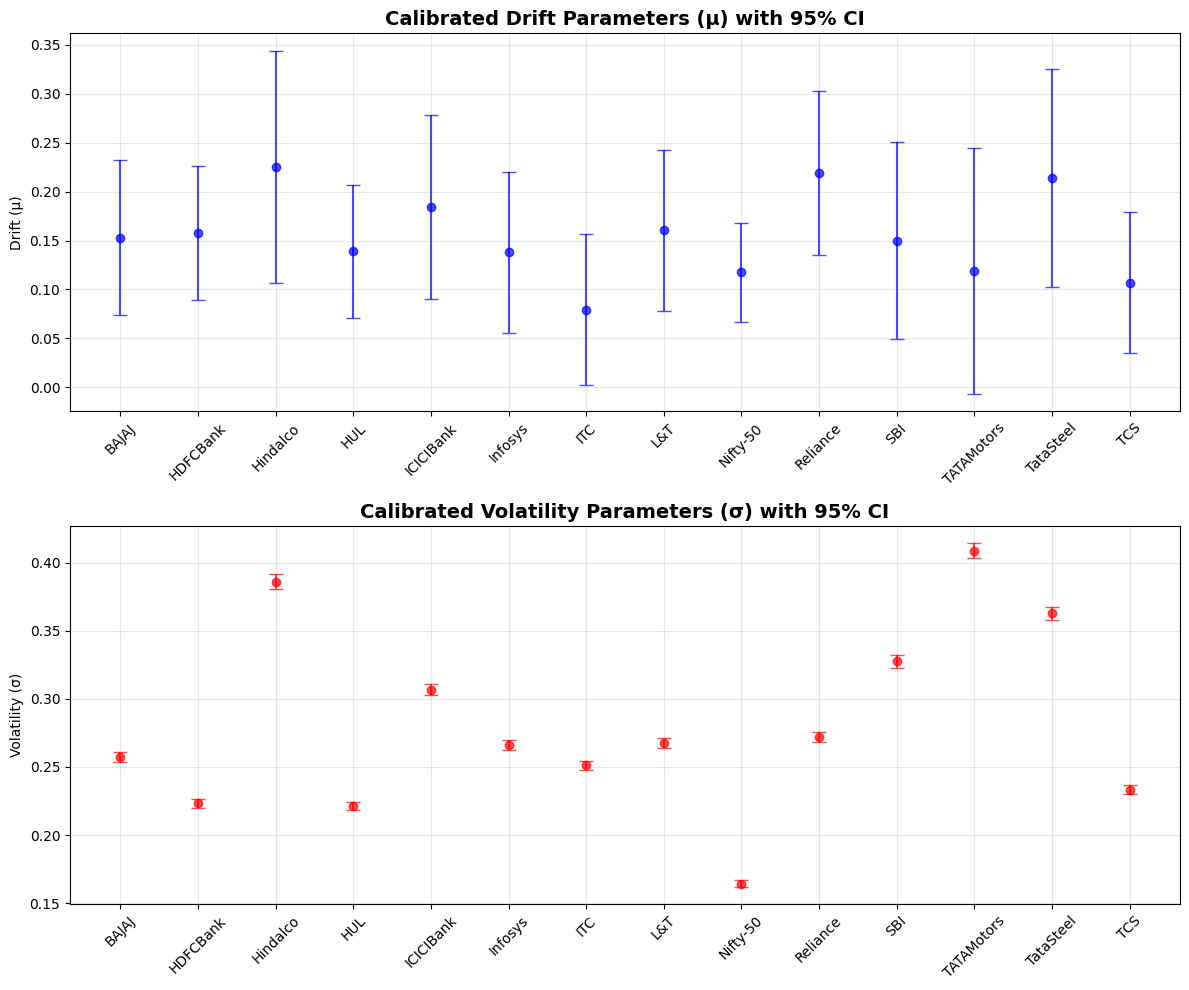


4. VALIDATING GBM SIMULATION METHODS...

Validating GBM methods for BAJAJ:
T = 1.0, dt = 0.0040, n_paths = 1000
  Euler-Maruyama final price: 2869.49
  Analytical final price: 2886.20
  Theoretical final price: 2856.19
  Method difference: 16.7074
  Relative difference: 0.0068

Validating GBM methods for HDFCBank:
T = 1.0, dt = 0.0040, n_paths = 1000
  Euler-Maruyama final price: 282.93
  Analytical final price: 281.02
  Theoretical final price: 281.23
  Method difference: 1.9053
  Relative difference: 0.0079

5. SAVING RESULTS...

✓ MLE Parameters saved to: gbm_step1_parameters_mle.csv

STEP 1 COMPLETED SUCCESSFULLY!
CORRECT MLE IMPLEMENTATION: μ = mean(r)/dt + 0.5*σ²


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

class GBM:
    def __init__(self, mu, sigma, S0):
        self.mu = mu
        self.sigma = sigma
        self.S0 = S0
      
    def simulate_euler_maruyama(self, T, dt, n_paths):
        """
        Euler-Maruyama discretization scheme for GBM
        dS_t = μS_t dt + σS_t dW_t
        """
        n_steps = int(T / dt)
        time_points = np.linspace(0, T, n_steps + 1)
        
        # Initialize paths
        paths = np.zeros((n_steps + 1, n_paths))
        paths[0] = self.S0
        
        # Brownian increments
        dW = np.random.normal(0, np.sqrt(dt), (n_steps, n_paths))
        
        # Euler-Maruyama scheme
        for t in range(1, n_steps + 1):
            paths[t] = paths[t-1] * (1 + self.mu * dt + self.sigma * dW[t-1])
        
        return time_points, paths
    
    def simulate_analytical(self, T, dt, n_paths):
        """
        Analytical solution for GBM using log-normal property
        S_t = S_0 * exp((μ - σ²/2)t + σW_t)
        """
        n_steps = int(T / dt)
        time_points = np.linspace(0, T, n_steps + 1)
        
        # Brownian motion
        W = np.zeros((n_steps + 1, n_paths))
        dW = np.random.normal(0, np.sqrt(dt), (n_steps, n_paths))
        
        # Cumulative Brownian motion
        for t in range(1, n_steps + 1):
            W[t] = W[t-1] + dW[t-1]
        
        # Analytical solution
        paths = self.S0 * np.exp((self.mu - 0.5 * self.sigma**2) * time_points.reshape(-1, 1) 
                               + self.sigma * W)
        
        return time_points, paths

class GBMCalibrator:
    """
    MLE Calibration for Geometric Brownian Motion
    """
    
    @staticmethod
    def mle_closed_form(log_returns, dt):
        """
        Closed-form MLE estimators for GBM parameters
        
        For log-returns: r_t = log(S_t/S_{t-1}) ~ N((μ - σ²/2)dt, σ²dt)
        
        MLE estimators:
        σ_hat = std(r_t) / sqrt(dt)
        μ_hat = (mean(r_t)/dt) + 0.5 * σ_hat²  [CORRECTED: includes convexity adjustment]
        """
        n = len(log_returns)
        
        # MLE for volatility (annualized)
        sigma_hat = np.std(log_returns) / np.sqrt(dt)
        
        # MLE for drift (annualized) - WITH convexity adjustment
        mu_hat = (np.mean(log_returns) / dt) + 0.5 * sigma_hat**2
        
        return mu_hat, sigma_hat
    
    @staticmethod
    def compute_confidence_intervals(log_returns, dt, alpha=0.05):
        """
        Compute confidence intervals using Fisher Information
        """
        n = len(log_returns)
        mu_hat, sigma_hat = GBMCalibrator.mle_closed_form(log_returns, dt)
        
        # Fisher Information matrix
        I_mu = n * dt / (sigma_hat**2)
        I_sigma = 2 * n / (sigma_hat**2)
        
        # Standard errors
        se_mu = 1 / np.sqrt(I_mu)
        se_sigma = 1 / np.sqrt(I_sigma)
        
        # Critical value (z-score for normal)
        z = stats.norm.ppf(1 - alpha/2)
        
        # Confidence intervals
        ci_mu = (mu_hat - z * se_mu, mu_hat + z * se_mu)
        ci_sigma = (sigma_hat - z * se_sigma, sigma_hat + z * se_sigma)
        
        return {
            'mu_ci': ci_mu,
            'sigma_ci': ci_sigma,
            'se_mu': se_mu,
            'se_sigma': se_sigma
        }

def read_and_prepare_data(folder_path):
    """
    Read all CSV files and prepare data for GBM analysis
    """
    files_to_process = [
        os.path.join(folder_path, f) for f in os.listdir(folder_path) 
        if f.endswith('-Data.csv')
    ]
    
    data_dict = {}
    print(f"Found {len(files_to_process)} return files to process...")
    
    for file_path in files_to_process:
        try:
            df = pd.read_csv(file_path)
            df['Date'] = pd.to_datetime(df['Date'])
            df.set_index('Date', inplace=True)
            
            # Extract asset name from filename
            asset_name = os.path.basename(file_path).replace('-Data.csv', '')
            data_dict[asset_name] = df
            
            print(f"  ✓ Loaded {asset_name}: {len(df)} observations")
            
        except Exception as e:
            print(f"  ✗ Failed to load {file_path}: {e}")
    
    return data_dict

def calibrate_gbm_parameters(data_dict):
    """
    Calibrate GBM parameters using MLE for each asset
    """
    parameters = {}
    dt_daily = 1/252  # Assuming daily data
    
    print("\nCALIBRATING GBM PARAMETERS USING MLE:")
    print("=" * 50)
    
    for asset_name, df in data_dict.items():
        returns = df['LOG'].values
        
        # MLE calibration with closed-form estimators
        mu_hat, sigma_hat = GBMCalibrator.mle_closed_form(returns, dt_daily)
        
        # Confidence intervals
        ci_results = GBMCalibrator.compute_confidence_intervals(returns, dt_daily)
        
        # Store results
        parameters[asset_name] = {
            'mu': mu_hat,
            'sigma': sigma_hat,
            'S0': df['Price'].iloc[0],
            'n_obs': len(returns),
            'mean_log_return': np.mean(returns),
            'std_log_return': np.std(returns),
            'mu_ci_lower': ci_results['mu_ci'][0],
            'mu_ci_upper': ci_results['mu_ci'][1],
            'sigma_ci_lower': ci_results['sigma_ci'][0],
            'sigma_ci_upper': ci_results['sigma_ci'][1],
            'se_mu': ci_results['se_mu'],
            'se_sigma': ci_results['se_sigma']
        }
        
        print(f"\n{asset_name}:")
        print(f"  μ (drift)    = {mu_hat:.4f} ± {ci_results['se_mu']:.4f}")
        print(f"   95% CI: [{ci_results['mu_ci'][0]:.4f}, {ci_results['mu_ci'][1]:.4f}]")
        print(f"  σ (volatility) = {sigma_hat:.4f} ± {ci_results['se_sigma']:.4f}")
        print(f"   95% CI: [{ci_results['sigma_ci'][0]:.4f}, {ci_results['sigma_ci'][1]:.4f}]")
        print(f"  S0 (initial price) = {df['Price'].iloc[0]:.2f}")
        
        # Show the importance of convexity adjustment
        mu_incorrect = np.mean(returns) / dt_daily  # INCORRECT: missing + 0.5*sigma²
        convexity_adjustment = 0.5 * sigma_hat**2
        print(f"  Convexity adjustment: +{convexity_adjustment:.4f}")
        print(f"  Incorrect μ (without adjustment): {mu_incorrect:.4f}")
        print(f"  Difference: {mu_hat - mu_incorrect:.4f}")
    
    return parameters

def validate_gbm_methods(parameters, asset_name):
    """
    Validate Euler-Maruyama vs Analytical methods for a given asset
    """
    mu = parameters[asset_name]['mu']
    sigma = parameters[asset_name]['sigma']
    S0 = parameters[asset_name]['S0']
    
    # Create GBM instance
    gbm = GBM(mu, sigma, S0)
    
    # Simulation parameters
    T = 1.0  # 1 year
    dt = 1/252  # Daily steps
    n_paths = 1000
    
    print(f"\nValidating GBM methods for {asset_name}:")
    print(f"T = {T}, dt = {dt:.4f}, n_paths = {n_paths}")
    
    # Simulate using both methods
    time_euler, paths_euler = gbm.simulate_euler_maruyama(T, dt, n_paths)
    time_analytical, paths_analytical = gbm.simulate_analytical(T, dt, n_paths)
    
    # Compare results
    comparison_results = {
        'final_price_euler_mean': np.mean(paths_euler[-1]),
        'final_price_analytical_mean': np.mean(paths_analytical[-1]),
        'final_price_std_euler': np.std(paths_euler[-1]),
        'final_price_std_analytical': np.std(paths_analytical[-1]),
        'expected_final_price': S0 * np.exp(mu * T),  # Theoretical expectation
        'method_difference': np.abs(np.mean(paths_euler[-1]) - np.mean(paths_analytical[-1])),
        'relative_difference': np.abs(np.mean(paths_euler[-1]) - np.mean(paths_analytical[-1])) / S0
    }
    
    print(f"  Euler-Maruyama final price: {comparison_results['final_price_euler_mean']:.2f}")
    print(f"  Analytical final price: {comparison_results['final_price_analytical_mean']:.2f}")
    print(f"  Theoretical final price: {comparison_results['expected_final_price']:.2f}")
    print(f"  Method difference: {comparison_results['method_difference']:.4f}")
    print(f"  Relative difference: {comparison_results['relative_difference']:.4f}")
    
    return gbm, time_euler, paths_euler, time_analytical, paths_analytical, comparison_results

def plot_calibration_results(parameters):
    """
    Plot calibrated parameters across all assets
    """
    assets = list(parameters.keys())
    mu_values = [parameters[asset]['mu'] for asset in assets]
    sigma_values = [parameters[asset]['sigma'] for asset in assets]
    mu_errors = [parameters[asset]['se_mu'] for asset in assets]
    sigma_errors = [parameters[asset]['se_sigma'] for asset in assets]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
    
    # Plot mu with confidence intervals
    ax1.errorbar(assets, mu_values, yerr=mu_errors, fmt='o', capsize=5, 
                color='blue', alpha=0.7)
    ax1.set_title('Calibrated Drift Parameters (μ) with 95% CI', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Drift (μ)')
    ax1.grid(True, alpha=0.3)
    ax1.tick_params(axis='x', rotation=45)
    
    # Plot sigma with confidence intervals
    ax2.errorbar(assets, sigma_values, yerr=sigma_errors, fmt='o', capsize=5, 
                color='red', alpha=0.7)
    ax2.set_title('Calibrated Volatility Parameters (σ) with 95% CI', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Volatility (σ)')
    ax2.grid(True, alpha=0.3)
    ax2.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.savefig('gbm_calibration_parameters.png', dpi=300, bbox_inches='tight')
    plt.show()

def save_step1_results(parameters, output_folder):
    """
    Save Step 1 results to CSV files
    """
    # Save parameters with confidence intervals
    params_data = []
    for asset_name, params in parameters.items():
        row = {
            'Asset': asset_name,
            'mu': params['mu'],
            'sigma': params['sigma'],
            'S0': params['S0'],
            'n_obs': params['n_obs'],
            'mu_ci_lower': params['mu_ci_lower'],
            'mu_ci_upper': params['mu_ci_upper'],
            'sigma_ci_lower': params['sigma_ci_lower'],
            'sigma_ci_upper': params['sigma_ci_upper'],
            'se_mu': params['se_mu'],
            'se_sigma': params['se_sigma'],
            'mean_log_return': params['mean_log_return'],
            'std_log_return': params['std_log_return']
        }
        params_data.append(row)
    
    params_df = pd.DataFrame(params_data)
    params_df.to_csv(os.path.join(output_folder, 'gbm_step1_parameters_mle.csv'), index=False)
    print(f"\n✓ MLE Parameters saved to: gbm_step1_parameters_mle.csv")
    
    return params_df

def main_step1():
    """
    Main function for Step 1 implementation with CORRECTED MLE
    """
    # Configuration
    data_folder = r"..\Data-Working"  # Your data folder
    output_folder = r"..\Data-Working\\GBM_Results"
    
    # Create output directory if it doesn't exist
    os.makedirs(output_folder, exist_ok=True)
    
    print("=" * 60)
    print("STEP 1: GBM BASIC IMPLEMENTATION & MLE CALIBRATION")
    print("=" * 60)
    
    # 1. Read and prepare data
    print("\n1. READING DATA...")
    data_dict = read_and_prepare_data(data_folder)
    
    if not data_dict:
        print("No data found! Please check your file paths.")
        return
    
    # 2. Calibrate GBM parameters using CORRECT MLE
    print("\n2. CALIBRATING PARAMETERS WITH MLE...")
    parameters = calibrate_gbm_parameters(data_dict)
    
    # 3. Plot calibration results
    print("\n3. PLOTTING CALIBRATION RESULTS...")
    plot_calibration_results(parameters)
    
    # 4. Validate GBM methods for first few assets
    print("\n4. VALIDATING GBM SIMULATION METHODS...")
    for asset_name in list(data_dict.keys())[:2]:  # Validate first 2 assets
        validate_gbm_methods(parameters, asset_name)
    
    # 5. Save results
    print("\n5. SAVING RESULTS...")
    params_df = save_step1_results(parameters, output_folder)
    
    print("\n" + "=" * 60)
    print("STEP 1 COMPLETED SUCCESSFULLY!")
    print("CORRECT MLE IMPLEMENTATION: μ = mean(r)/dt + 0.5*σ²")
    print("=" * 60)
    
    return params_df

# Run Step 1
if __name__ == "__main__":
    main_step1()

STEPS 2 & 3: GBM VALIDATION & COMPREHENSIVE ANALYSIS

1. READING DATA...
Found 14 return files to process...
  ✓ Loaded BAJAJ: 2664 observations
  ✓ Loaded HDFCBank: 2665 observations
  ✓ Loaded Hindalco: 2664 observations
  ✓ Loaded HUL: 2664 observations
  ✓ Loaded ICICIBank: 2664 observations
  ✓ Loaded Infosys: 2664 observations
  ✓ Loaded ITC: 2665 observations
  ✓ Loaded L&T: 2664 observations
  ✓ Loaded Nifty-50: 2665 observations
  ✓ Loaded Reliance: 2665 observations
  ✓ Loaded SBI: 2665 observations
  ✓ Loaded TATAMotors: 2664 observations
  ✓ Loaded TataSteel: 2665 observations
  ✓ Loaded TCS: 2664 observations

2. CALIBRATING PARAMETERS...

CALIBRATING GBM PARAMETERS USING MLE:

3. PERFORMING GOODNESS-OF-FIT TESTS...

--- Goodness-of-Fit Tests for BAJAJ ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0706, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 8311.6227, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9283, p-value: 0

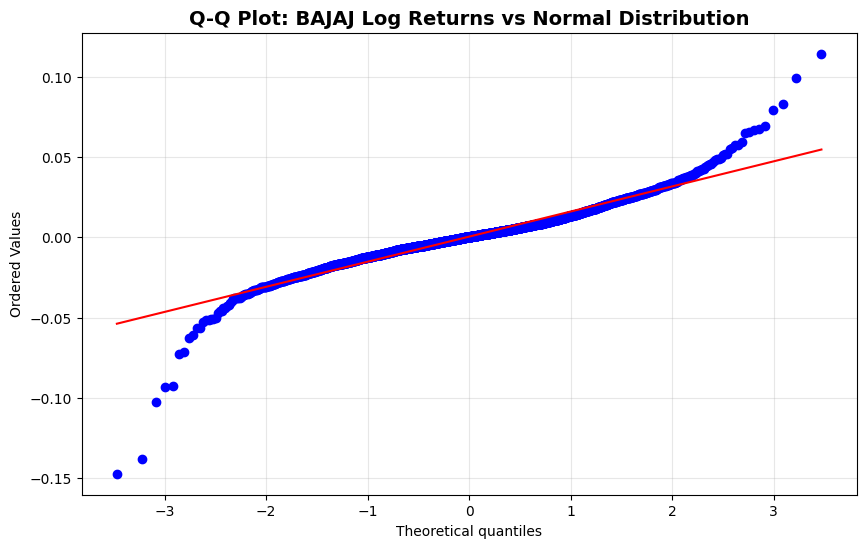


--- Goodness-of-Fit Tests for HDFCBank ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0716, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 12714.3880, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9092, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.3372
  Kurtosis: 10.6792


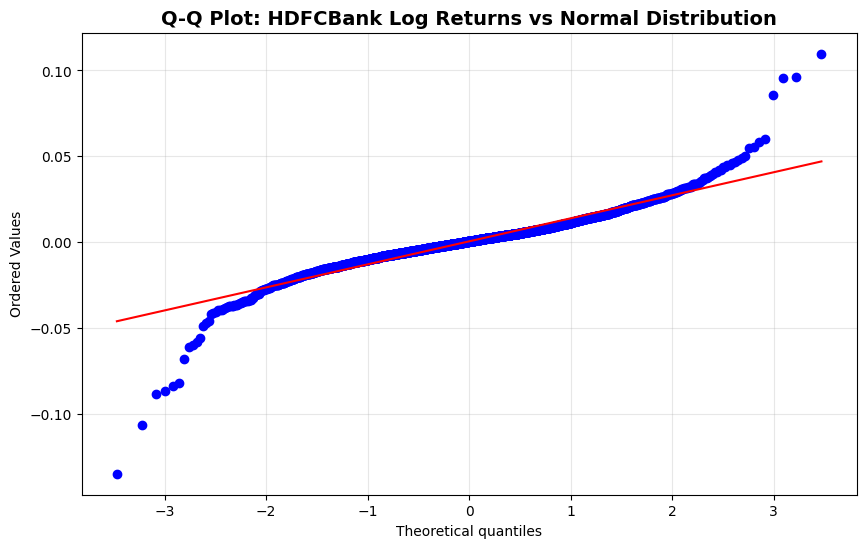


--- Goodness-of-Fit Tests for Hindalco ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0536, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 1653.4320, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9658, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.2013
  Kurtosis: 3.8384


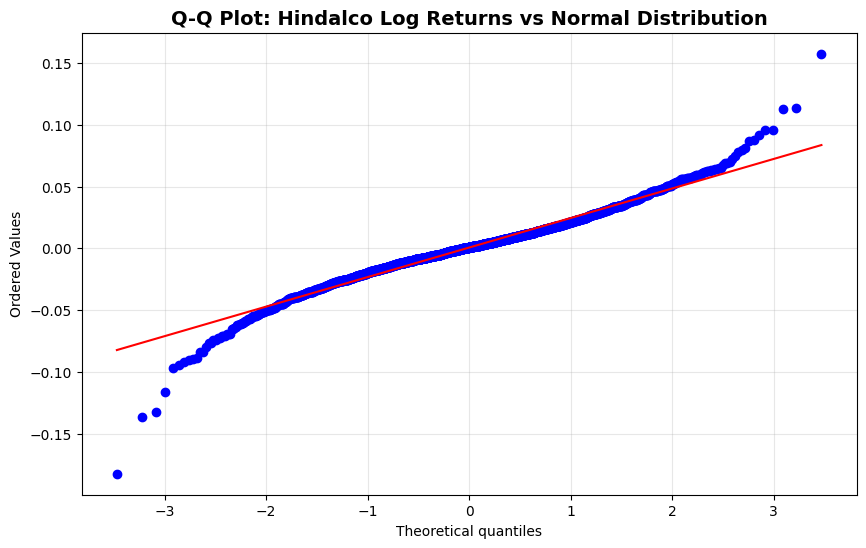


--- Goodness-of-Fit Tests for HUL ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0578, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 4974.2841, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9470, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.6406
  Kurtosis: 6.5705


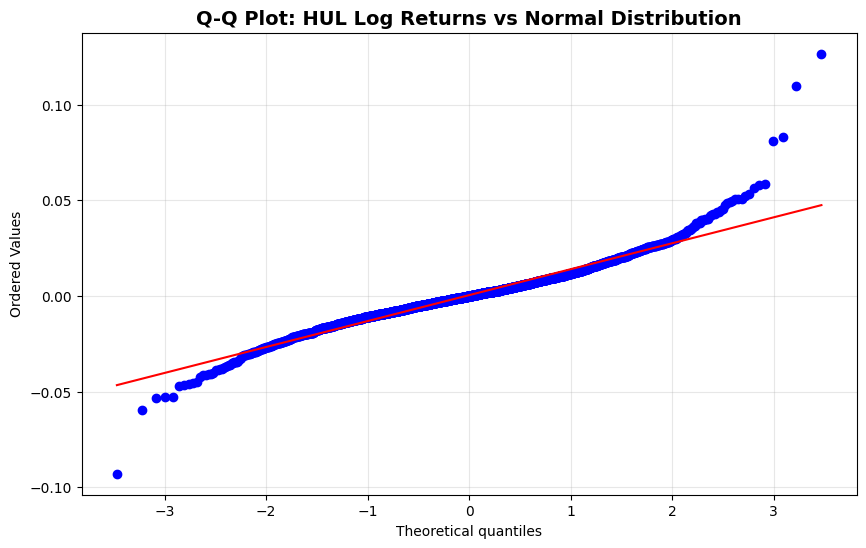


--- Goodness-of-Fit Tests for ICICIBank ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0715, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 9649.8743, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9187, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.1117
  Kurtosis: 9.3213


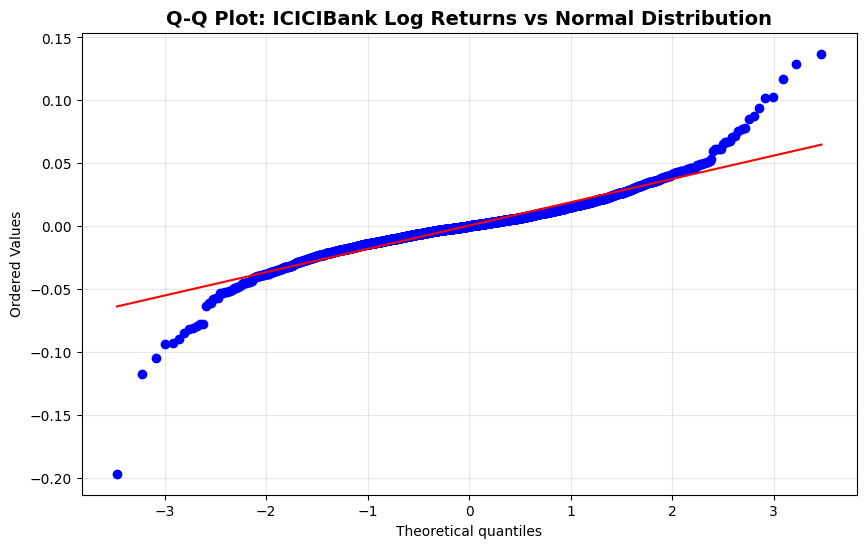


--- Goodness-of-Fit Tests for Infosys ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0591, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 11081.2100, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9228, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.5421
  Kurtosis: 9.9325


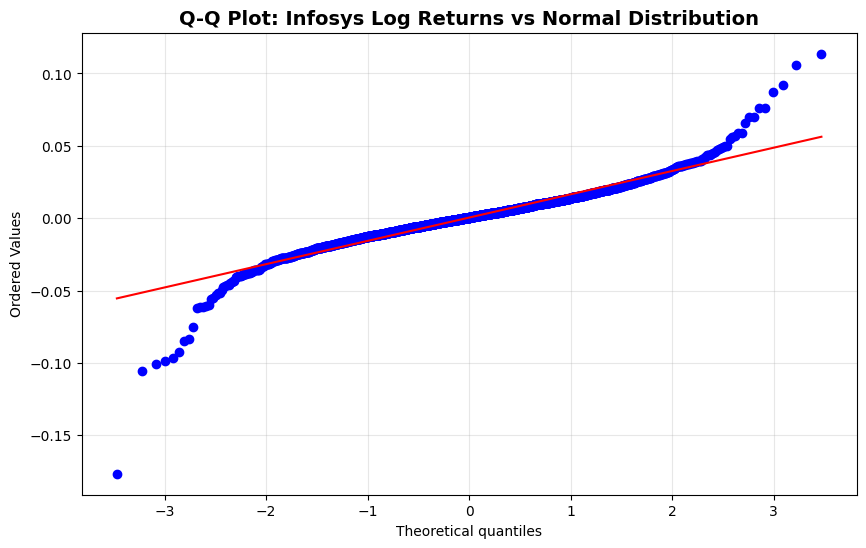


--- Goodness-of-Fit Tests for ITC ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0686, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 7558.4935, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9229, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.4537
  Kurtosis: 8.2003


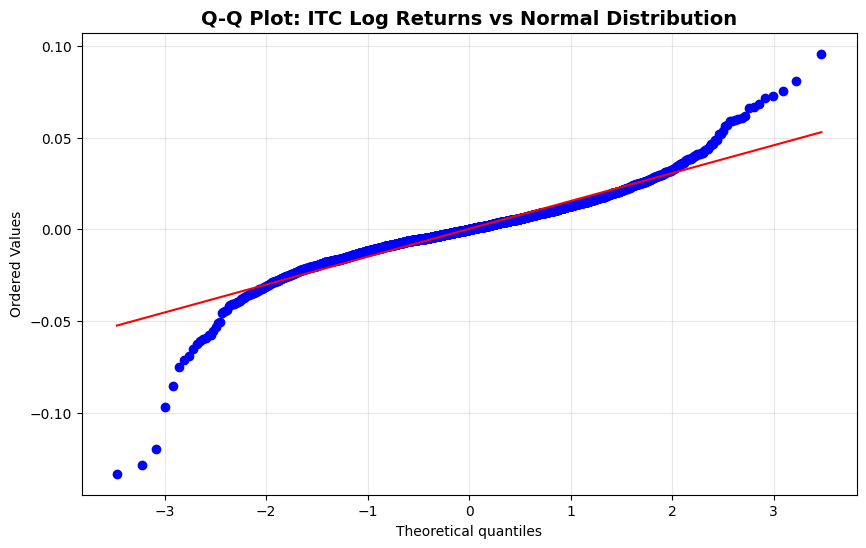


--- Goodness-of-Fit Tests for L&T ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0637, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 11335.2026, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9244, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.2167
  Kurtosis: 10.0961


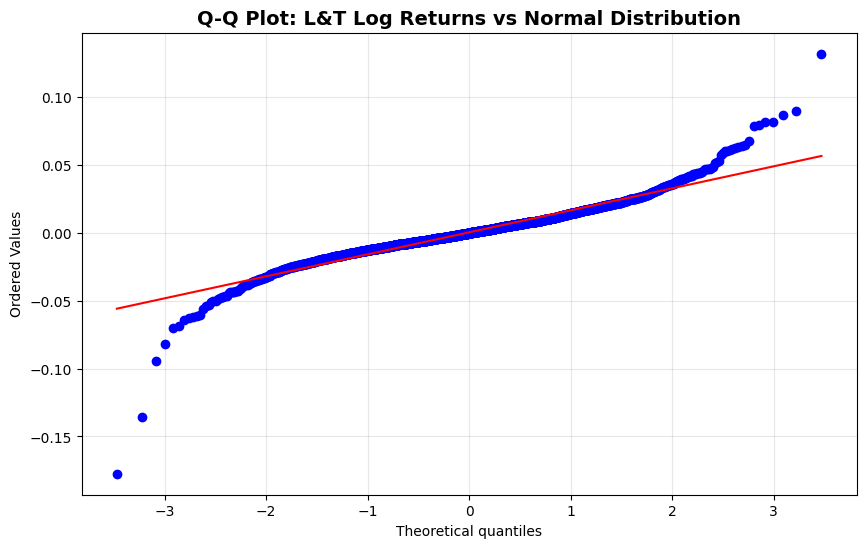


--- Goodness-of-Fit Tests for Nifty-50 ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0779, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 46632.1090, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.8808, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -1.3616
  Kurtosis: 20.3110


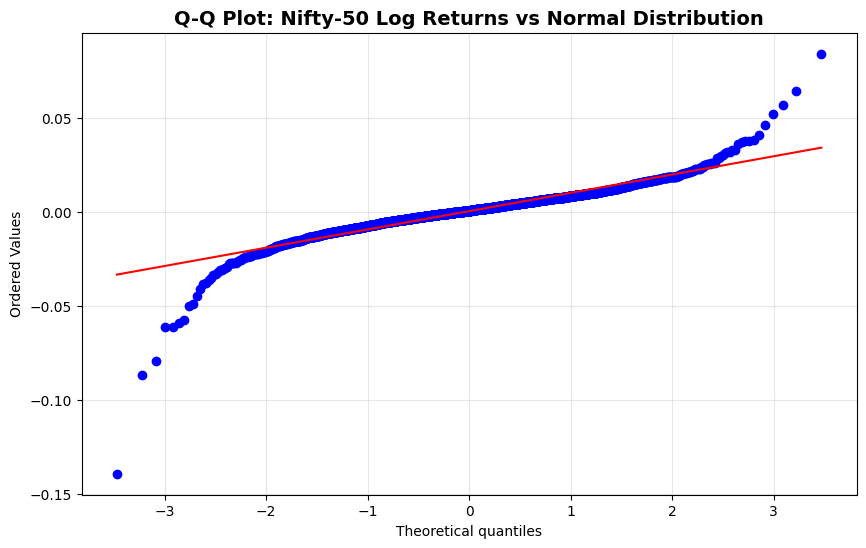


--- Goodness-of-Fit Tests for Reliance ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0567, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 7857.9964, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9272, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.0882
  Kurtosis: 8.4104


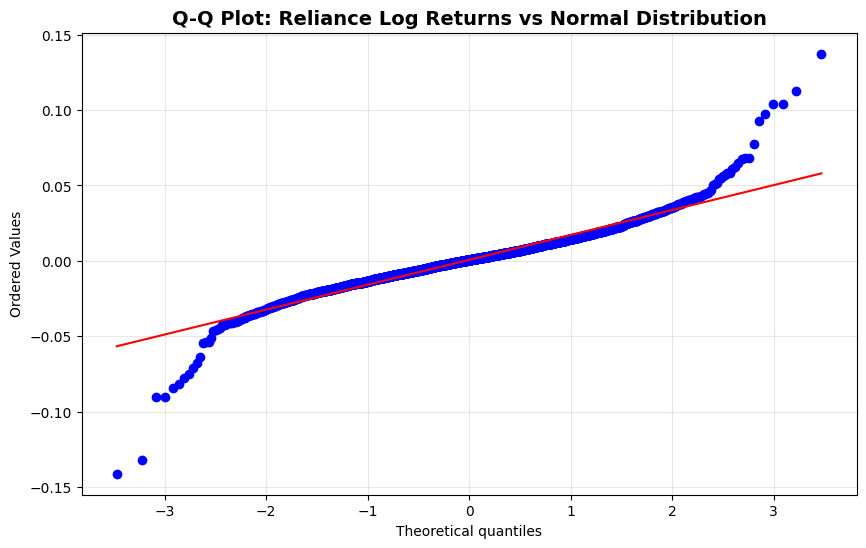


--- Goodness-of-Fit Tests for SBI ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0655, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 16931.7401, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9211, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.4490
  Kurtosis: 12.3156


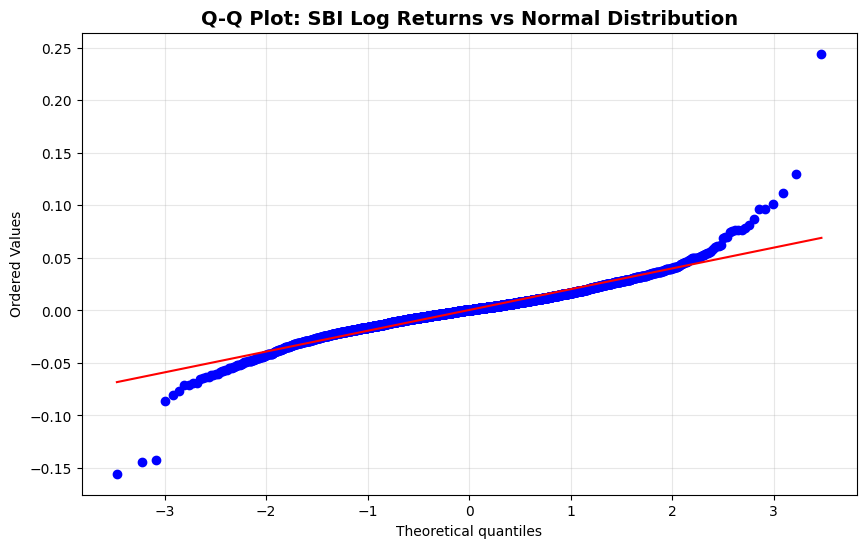


--- Goodness-of-Fit Tests for TATAMotors ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0698, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 5082.2727, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9287, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.1510
  Kurtosis: 6.7598


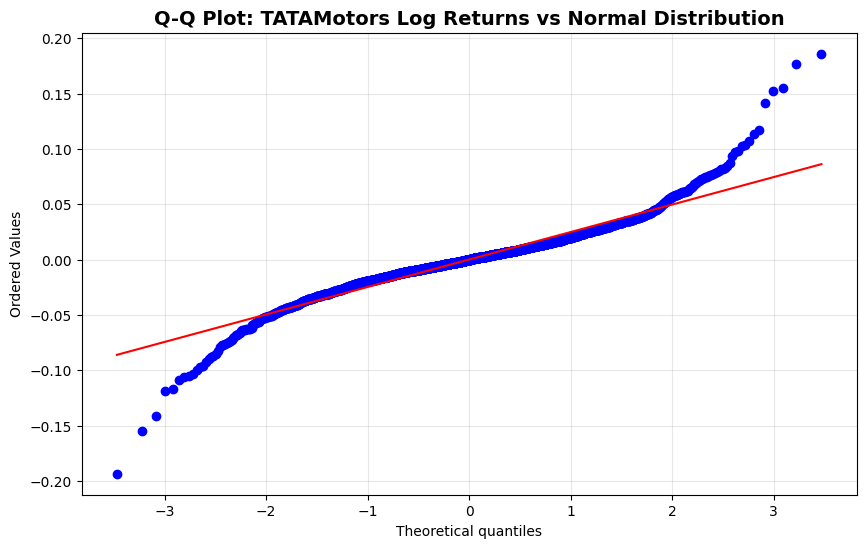


--- Goodness-of-Fit Tests for TataSteel ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0591, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 1251.4367, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9624, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.2044
  Kurtosis: 3.3321


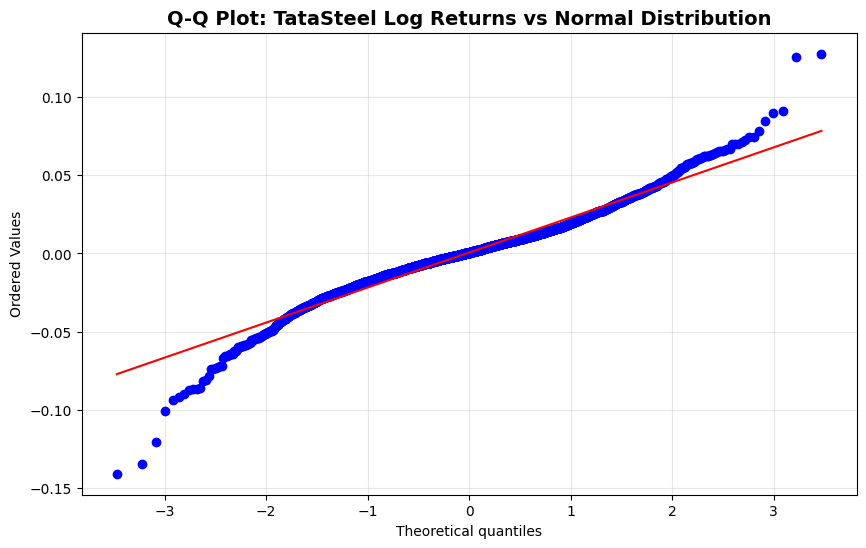


--- Goodness-of-Fit Tests for TCS ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0547, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 1468.5517, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9623, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.0436
  Kurtosis: 3.6363


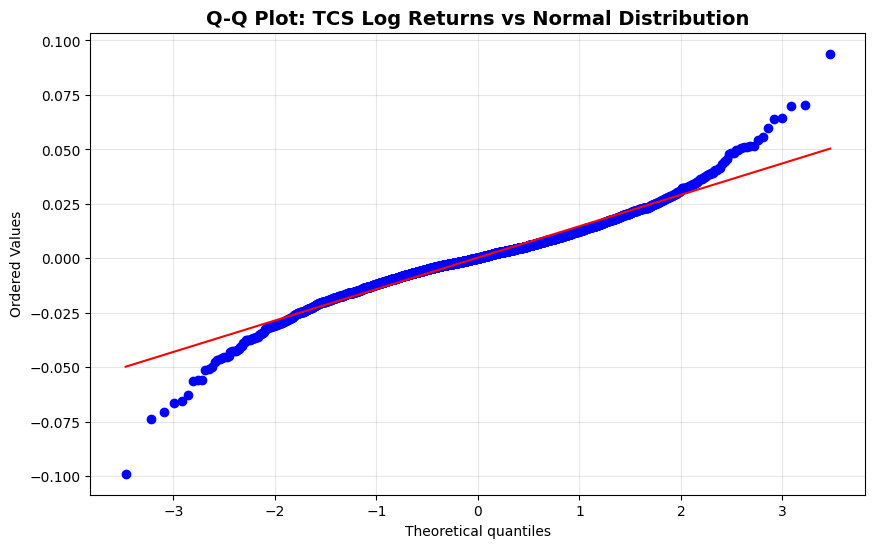


4. SIMULATION VALIDATION...

BAJAJ Simulation Validation:
  Actual mean return: 0.000475
  Simulated mean return: 0.123226
  Actual final price: 8679.50
  Simulated final price: 12964.22 ± 13768.69
  Price coverage (80-120%): 18.30%


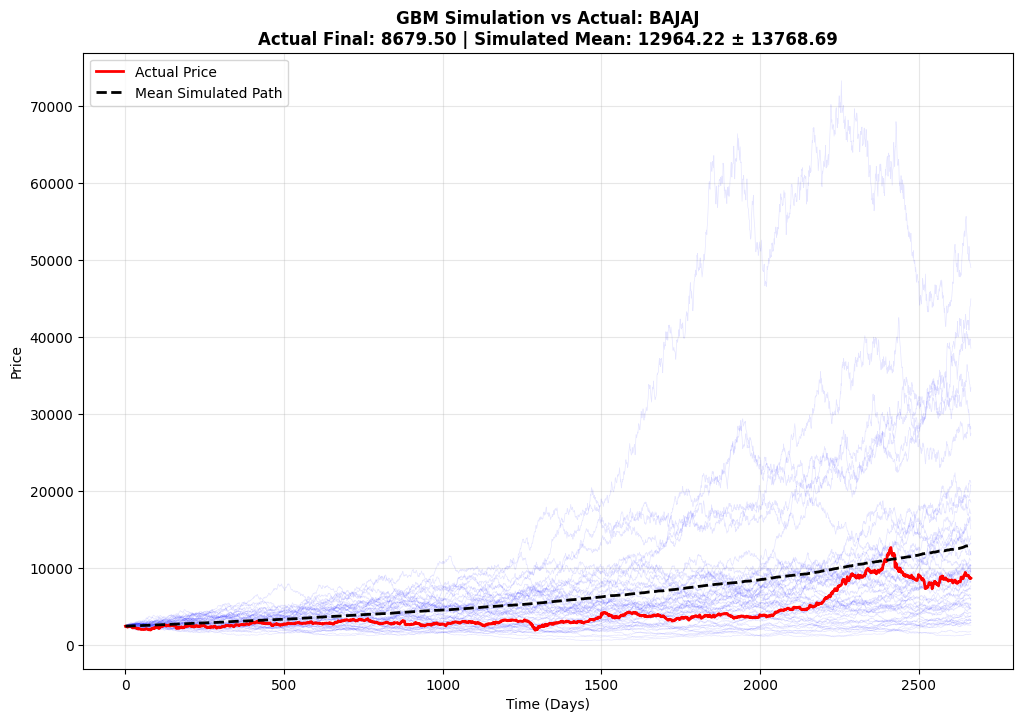


HDFCBank Simulation Validation:
  Actual mean return: 0.000522
  Simulated mean return: 0.133742
  Actual final price: 965.15
  Simulated final price: 1264.53 ± 1003.57
  Price coverage (80-120%): 23.30%


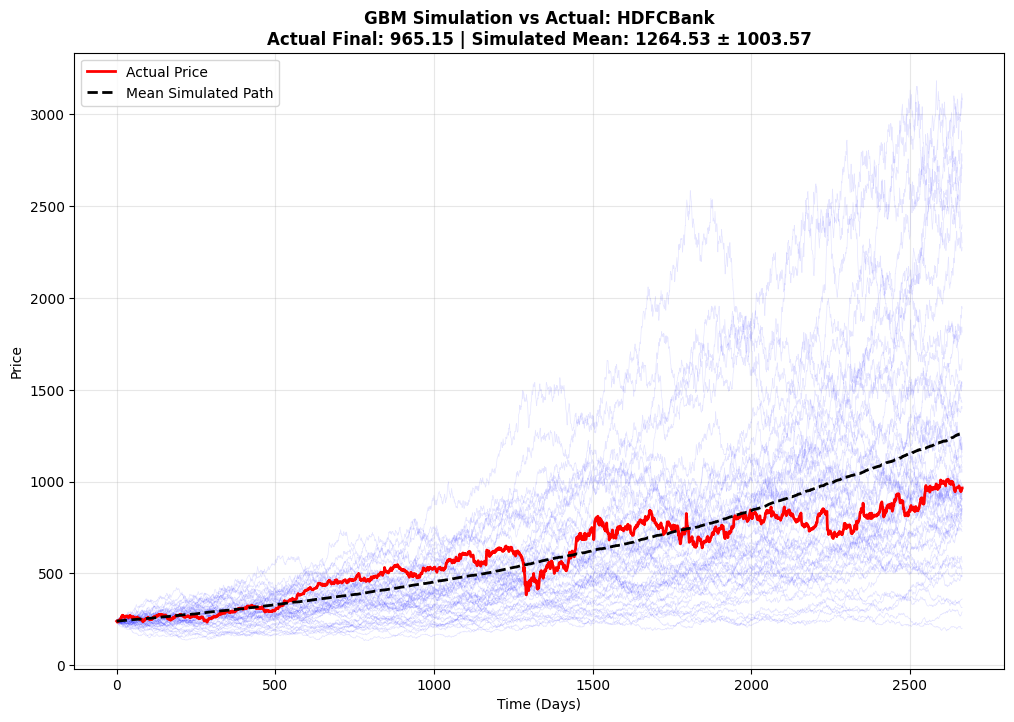


Hindalco Simulation Validation:
  Actual mean return: 0.000595
  Simulated mean return: 0.144414
  Actual final price: 780.35
  Simulated final price: 1586.01 ± 2672.11
  Price coverage (80-120%): 11.00%


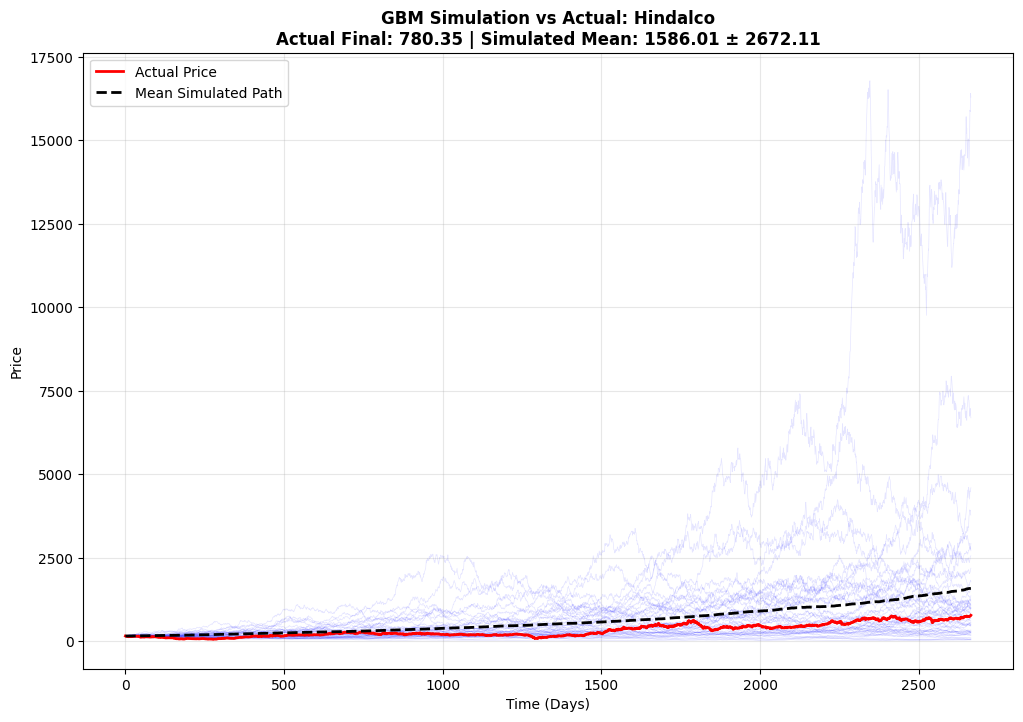


5. FORECAST EVALUATION...

--- Forecast Evaluation for BAJAJ ---
RMSE: 147.00
MAE: 98.47
MAPE: 1.17%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for HDFCBank ---
RMSE: 10.16
MAE: 7.24
MAPE: 0.87%
Training period: 2132 days
Testing period: 532 days

--- Forecast Evaluation for Hindalco ---
RMSE: 11.47
MAE: 8.03
MAPE: 1.30%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for HUL ---
RMSE: 29.10
MAE: 20.75
MAPE: 0.84%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for ICICIBank ---
RMSE: 13.98
MAE: 9.85
MAPE: 0.82%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for Infosys ---
RMSE: 24.43
MAE: 17.52
MAPE: 1.08%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for ITC ---
RMSE: 5.70
MAE: 3.87
MAPE: 0.91%
Training period: 2132 days
Testing period: 532 days

--- Forecast Evaluation for L&T ---
RMSE: 55.46
MAE: 38.13
MAPE: 1.10%
Training period

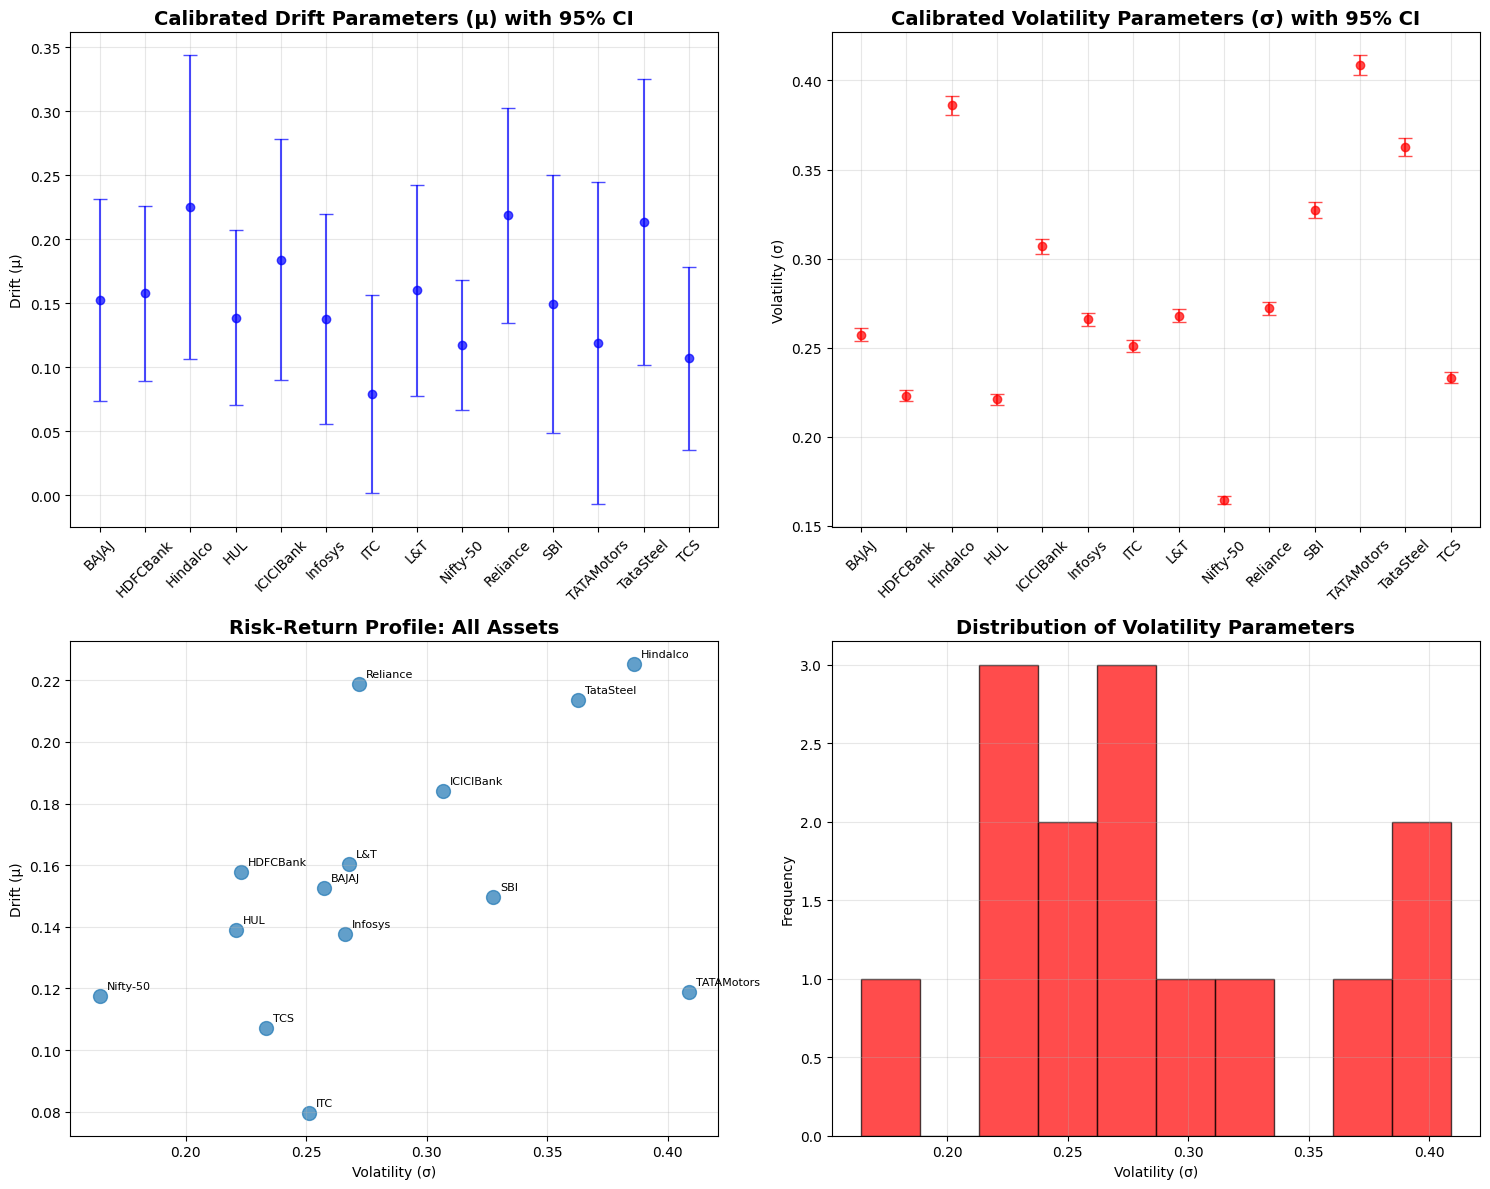

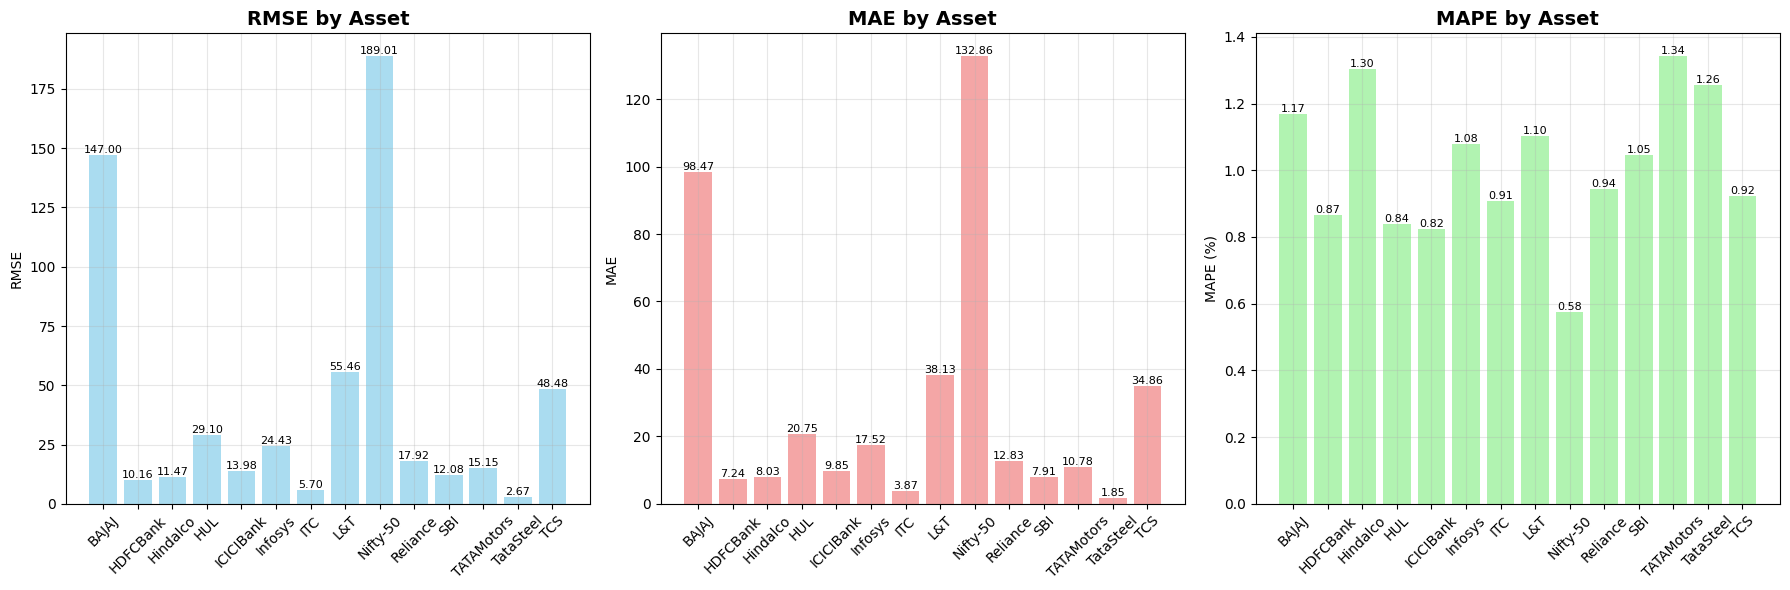

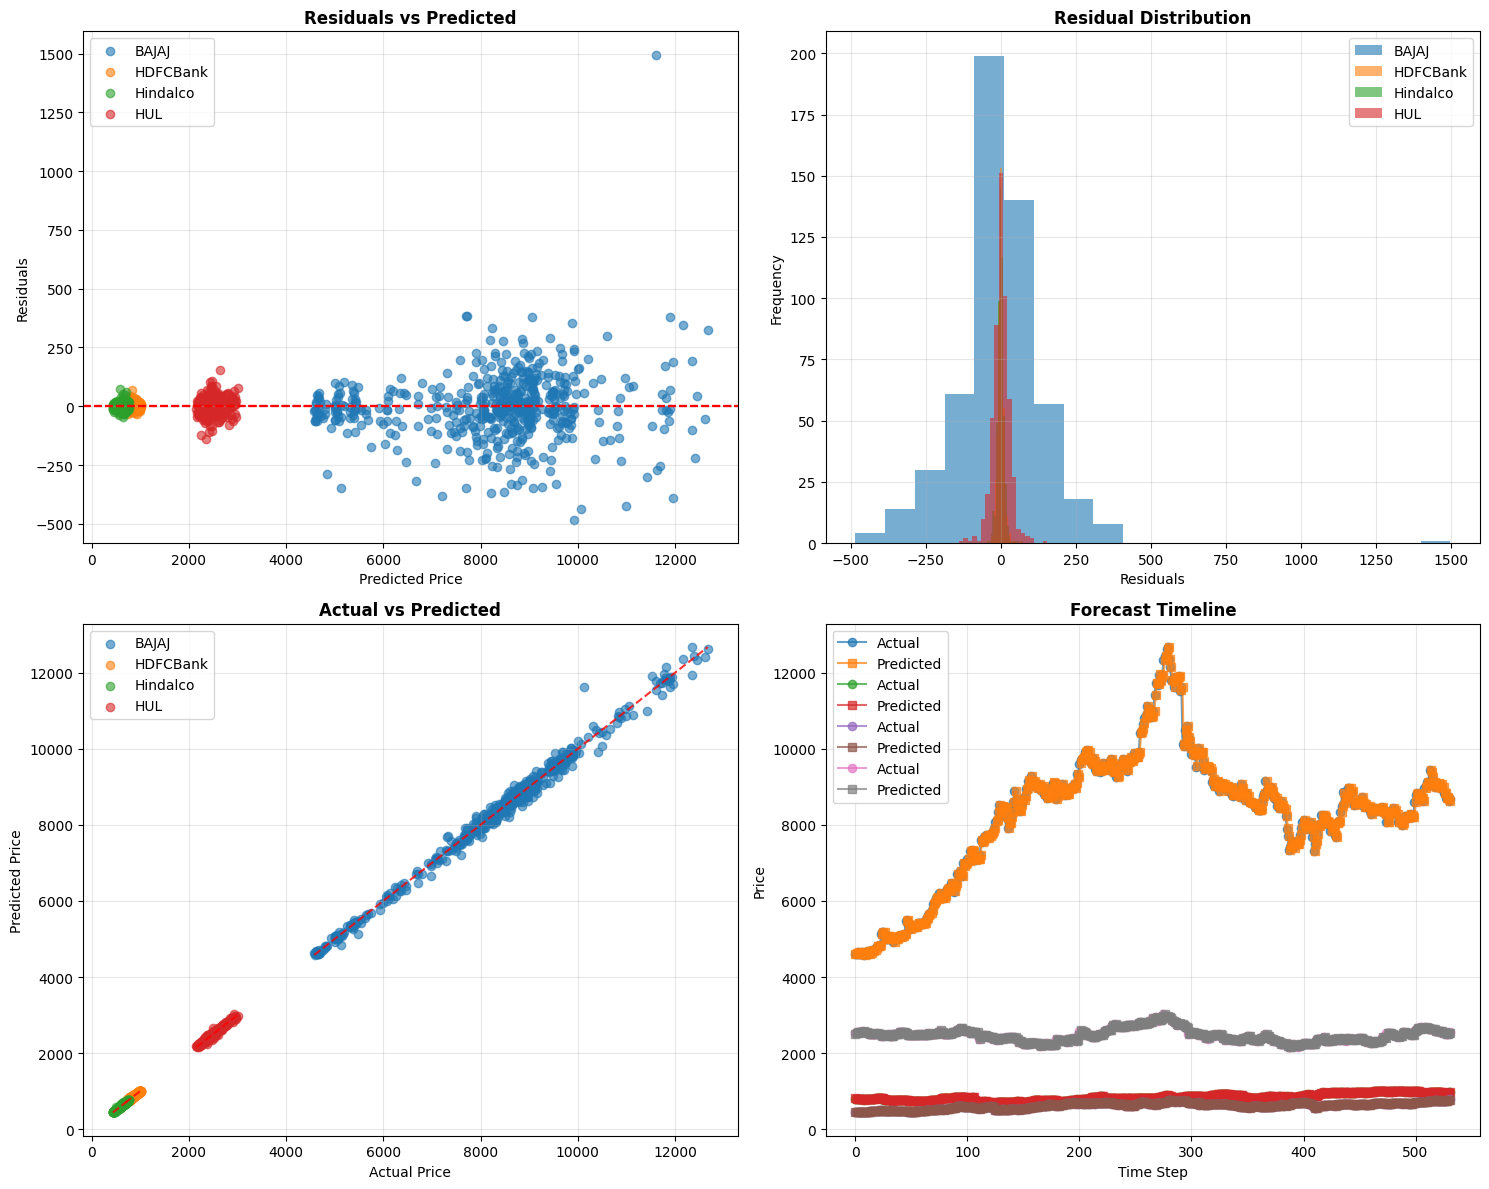


7. GENERATING SUMMARY REPORT...
✓ Comprehensive report saved to: ..\Data-Working\\GBM_Results\gbm_analysis_report.txt

STEPS 2 & 3 COMPLETED SUCCESSFULLY!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# =============================================================================
# STEP 1: EXISTING IMPLEMENTATION (for reference)
# =============================================================================

class GBM:
    def __init__(self, mu, sigma, S0):
        self.mu = mu
        self.sigma = sigma
        self.S0 = S0
      
    def simulate_euler_maruyama(self, T, dt, n_paths):
        """
        Euler-Maruyama discretization scheme for GBM
        dS_t = μS_t dt + σS_t dW_t
        """
        n_steps = int(T / dt)
        time_points = np.linspace(0, T, n_steps + 1)
        
        # Initialize paths
        paths = np.zeros((n_steps + 1, n_paths))
        paths[0] = self.S0
        
        # Brownian increments
        dW = np.random.normal(0, np.sqrt(dt), (n_steps, n_paths))
        
        # Euler-Maruyama scheme
        for t in range(1, n_steps + 1):
            paths[t] = paths[t-1] * (1 + self.mu * dt + self.sigma * dW[t-1])
        
        return time_points, paths
    
    def simulate_analytical(self, T, dt, n_paths):
        """
        Analytical solution for GBM using log-normal property
        S_t = S_0 * exp((μ - σ²/2)t + σW_t)
        """
        n_steps = int(T / dt)
        time_points = np.linspace(0, T, n_steps + 1)
        
        # Brownian motion
        W = np.zeros((n_steps + 1, n_paths))
        dW = np.random.normal(0, np.sqrt(dt), (n_steps, n_paths))
        
        # Cumulative Brownian motion
        for t in range(1, n_steps + 1):
            W[t] = W[t-1] + dW[t-1]
        
        # Analytical solution
        paths = self.S0 * np.exp((self.mu - 0.5 * self.sigma**2) * time_points.reshape(-1, 1) 
                               + self.sigma * W)
        
        return time_points, paths

class GBMCalibrator:
    """
    MLE Calibration for Geometric Brownian Motion
    """
    
    @staticmethod
    def mle_closed_form(log_returns, dt):
        """
        Closed-form MLE estimators for GBM parameters
        """
        n = len(log_returns)
        
        # MLE for volatility (annualized)
        sigma_hat = np.std(log_returns) / np.sqrt(dt)
        
        # MLE for drift (annualized) - WITH convexity adjustment
        mu_hat = (np.mean(log_returns) / dt) + 0.5 * sigma_hat**2
        
        return mu_hat, sigma_hat
    
    @staticmethod
    def compute_confidence_intervals(log_returns, dt, alpha=0.05):
        """
        Compute confidence intervals using Fisher Information
        """
        n = len(log_returns)
        mu_hat, sigma_hat = GBMCalibrator.mle_closed_form(log_returns, dt)
        
        # Fisher Information matrix
        I_mu = n * dt / (sigma_hat**2)
        I_sigma = 2 * n / (sigma_hat**2)
        
        # Standard errors
        se_mu = 1 / np.sqrt(I_mu)
        se_sigma = 1 / np.sqrt(I_sigma)
        
        # Critical value (z-score for normal)
        z = stats.norm.ppf(1 - alpha/2)
        
        # Confidence intervals
        ci_mu = (mu_hat - z * se_mu, mu_hat + z * se_mu)
        ci_sigma = (sigma_hat - z * se_sigma, sigma_hat + z * se_sigma)
        
        return {
            'mu_ci': ci_mu,
            'sigma_ci': ci_sigma,
            'se_mu': se_mu,
            'se_sigma': se_sigma
        }

# =============================================================================
# STEP 2: GBM VALIDATION & TESTING
# =============================================================================

class GBMValidator:
    """
    Comprehensive validation of GBM model assumptions and performance
    """
    
    @staticmethod
    def goodness_of_fit_tests(log_returns, asset_name, alpha=0.05):
        """
        Perform statistical tests for normality assumption
        """
        print(f"\n--- Goodness-of-Fit Tests for {asset_name} ---")
        
        results = {}
        
        # 1. Kolmogorov-Smirnov test for normality
        ks_stat, ks_pvalue = stats.kstest(log_returns, 'norm', 
                                         args=(np.mean(log_returns), np.std(log_returns)))
        results['ks_test'] = {
            'statistic': ks_stat,
            'p_value': ks_pvalue,
            'reject_normal': ks_pvalue < alpha
        }
        print(f"Kolmogorov-Smirnov Test:")
        print(f"  Statistic: {ks_stat:.4f}, p-value: {ks_pvalue:.4f}")
        print(f"  Reject normality: {ks_pvalue < alpha}")
        
        # 2. Jarque-Bera test for normality
        jb_stat, jb_pvalue = stats.jarque_bera(log_returns)
        results['jb_test'] = {
            'statistic': jb_stat,
            'p_value': jb_pvalue,
            'reject_normal': jb_pvalue < alpha
        }
        print(f"Jarque-Bera Test:")
        print(f"  Statistic: {jb_stat:.4f}, p-value: {jb_pvalue:.4f}")
        print(f"  Reject normality: {jb_pvalue < alpha}")
        
        # 3. Shapiro-Wilk test (additional normality test)
        shapiro_stat, shapiro_pvalue = stats.shapiro(log_returns)
        results['shapiro_test'] = {
            'statistic': shapiro_stat,
            'p_value': shapiro_pvalue,
            'reject_normal': shapiro_pvalue < alpha
        }
        print(f"Shapiro-Wilk Test:")
        print(f"  Statistic: {shapiro_stat:.4f}, p-value: {shapiro_pvalue:.4f}")
        print(f"  Reject normality: {shapiro_pvalue < alpha}")
        
        # 4. Additional statistics
        results['descriptive_stats'] = {
            'skewness': stats.skew(log_returns),
            'kurtosis': stats.kurtosis(log_returns),
            'mean': np.mean(log_returns),
            'std': np.std(log_returns)
        }
        print(f"Descriptive Statistics:")
        print(f"  Skewness: {results['descriptive_stats']['skewness']:.4f}")
        print(f"  Kurtosis: {results['descriptive_stats']['kurtosis']:.4f}")
        
        return results
    
    @staticmethod
    def plot_qq(log_returns, asset_name, save_path=None):
        """
        Create QQ-plot for visual normality assessment
        """
        plt.figure(figsize=(10, 6))
        
        # Create QQ plot
        stats.probplot(log_returns, dist="norm", plot=plt)
        plt.title(f'Q-Q Plot: {asset_name} Log Returns vs Normal Distribution', 
                 fontsize=14, fontweight='bold')
        plt.grid(True, alpha=0.3)
        
        if save_path:
            plt.savefig(os.path.join(save_path, f'qq_plot_{asset_name}.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def simulation_validation(gbm_model, actual_prices, T, dt, n_paths=1000):
        """
        Compare simulated paths with actual data
        """
        # Simulate paths using analytical method (more accurate)
        time_points, simulated_paths = gbm_model.simulate_analytical(T, dt, n_paths)
        
        # Calculate actual and simulated returns
        actual_returns = np.diff(np.log(actual_prices))
        simulated_final_returns = np.log(simulated_paths[-1] / gbm_model.S0)
        
        # Statistical comparison
        comparison = {
            'actual_mean_return': np.mean(actual_returns),
            'simulated_mean_return': np.mean(simulated_final_returns) / T,
            'actual_std_return': np.std(actual_returns),
            'simulated_std_return': np.std(simulated_final_returns) / np.sqrt(T),
            'actual_final_price': actual_prices[-1],
            'simulated_final_price_mean': np.mean(simulated_paths[-1]),
            'simulated_final_price_std': np.std(simulated_paths[-1]),
            'price_coverage': np.mean((simulated_paths[-1] >= actual_prices[-1] * 0.8) & 
                                     (simulated_paths[-1] <= actual_prices[-1] * 1.2))
        }
        
        return time_points, simulated_paths, comparison
    
    @staticmethod
    def forecast_evaluation(data_dict, parameters, train_ratio=0.8):
        """
        Perform 1-day ahead forecasting and compute error metrics
        """
        forecast_results = {}
        dt_daily = 1/252
        
        for asset_name, df in data_dict.items():
            print(f"\n--- Forecast Evaluation for {asset_name} ---")
            
            # Split data into training and testing
            n_train = int(len(df) * train_ratio)
            train_data = df.iloc[:n_train]
            test_data = df.iloc[n_train:]
            
            # Recalibrate on training data only
            train_returns = train_data['LOG'].values
            mu_train, sigma_train = GBMCalibrator.mle_closed_form(train_returns, dt_daily)
            S0_test = test_data['Price'].iloc[0]
            
            # Create GBM model with training parameters
            gbm = GBM(mu_train, sigma_train, S0_test)
            
            # 1-day ahead predictions
            actual_prices = test_data['Price'].values
            n_test = len(actual_prices) - 1
            
            predicted_prices = []
            actual_next_prices = []
            
            current_price = S0_test
            for i in range(n_test):
                # Simulate one day ahead
                _, one_day_path = gbm.simulate_analytical(1/252, 1/252, 1000)
                predicted_price = np.mean(one_day_path[-1])
                predicted_prices.append(predicted_price)
                actual_next_prices.append(actual_prices[i+1])
                
                # Update current price for next prediction (rolling forecast)
                current_price = actual_prices[i+1]
                gbm.S0 = current_price
            
            predicted_prices = np.array(predicted_prices)
            actual_next_prices = np.array(actual_next_prices)
            
            # Calculate error metrics
            mse = np.mean((predicted_prices - actual_next_prices) ** 2)
            rmse = np.sqrt(mse)
            mae = np.mean(np.abs(predicted_prices - actual_next_prices))
            mape = np.mean(np.abs((predicted_prices - actual_next_prices) / actual_next_prices)) * 100
            
            forecast_results[asset_name] = {
                'rmse': rmse,
                'mae': mae,
                'mape': mape,
                'mse': mse,
                'predicted_prices': predicted_prices,
                'actual_prices': actual_next_prices,
                'train_size': n_train,
                'test_size': n_test
            }
            
            print(f"RMSE: {rmse:.2f}")
            print(f"MAE: {mae:.2f}")
            print(f"MAPE: {mape:.2f}%")
            print(f"Training period: {n_train} days")
            print(f"Testing period: {n_test} days")
        
        return forecast_results

# =============================================================================
# STEP 3: COMPREHENSIVE VISUALIZATION & REPORTING
# =============================================================================

class GBMVisualizer:
    """
    Create comprehensive visualizations for GBM analysis
    """
    
    @staticmethod
    def plot_calibration_summary(parameters):
        """
        Enhanced calibration results visualization
        """
        assets = list(parameters.keys())
        mu_values = [parameters[asset]['mu'] for asset in assets]
        sigma_values = [parameters[asset]['sigma'] for asset in assets]
        mu_errors = [parameters[asset]['se_mu'] for asset in assets]
        sigma_errors = [parameters[asset]['se_sigma'] for asset in assets]
        
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
        
        # Plot 1: Mu with confidence intervals
        ax1.errorbar(range(len(assets)), mu_values, yerr=mu_errors, fmt='o', 
                    capsize=5, color='blue', alpha=0.7)
        ax1.set_title('Calibrated Drift Parameters (μ) with 95% CI', 
                     fontsize=14, fontweight='bold')
        ax1.set_ylabel('Drift (μ)')
        ax1.set_xticks(range(len(assets)))
        ax1.set_xticklabels(assets, rotation=45)
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Sigma with confidence intervals
        ax2.errorbar(range(len(assets)), sigma_values, yerr=sigma_errors, fmt='o', 
                    capsize=5, color='red', alpha=0.7)
        ax2.set_title('Calibrated Volatility Parameters (σ) with 95% CI', 
                     fontsize=14, fontweight='bold')
        ax2.set_ylabel('Volatility (σ)')
        ax2.set_xticks(range(len(assets)))
        ax2.set_xticklabels(assets, rotation=45)
        ax2.grid(True, alpha=0.3)
        
        # Plot 3: Risk-Return scatter
        ax3.scatter(sigma_values, mu_values, s=100, alpha=0.7)
        for i, asset in enumerate(assets):
            ax3.annotate(asset, (sigma_values[i], mu_values[i]), 
                        xytext=(5, 5), textcoords='offset points', fontsize=8)
        ax3.set_xlabel('Volatility (σ)')
        ax3.set_ylabel('Drift (μ)')
        ax3.set_title('Risk-Return Profile: All Assets', fontsize=14, fontweight='bold')
        ax3.grid(True, alpha=0.3)
        
        # Plot 4: Parameter distribution
        ax4.hist(sigma_values, bins=10, alpha=0.7, color='red', edgecolor='black')
        ax4.set_xlabel('Volatility (σ)')
        ax4.set_ylabel('Frequency')
        ax4.set_title('Distribution of Volatility Parameters', 
                     fontsize=14, fontweight='bold')
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('gbm_comprehensive_calibration.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_simulation_vs_actual(asset_name, actual_prices, time_points, 
                                simulated_paths, comparison, save_path=None):
        """
        Plot simulated paths vs actual price trajectory
        """
        plt.figure(figsize=(12, 8))
        
        # Plot simulated paths (first 50 for clarity)
        n_paths_to_plot = min(50, simulated_paths.shape[1])
        for i in range(n_paths_to_plot):
            plt.plot(time_points * 252, simulated_paths[:, i], 
                    alpha=0.1, color='blue', linewidth=0.5)
        
        # Plot actual price trajectory
        actual_time = np.linspace(0, time_points[-1], len(actual_prices)) * 252
        plt.plot(actual_time, actual_prices, 'r-', linewidth=2, label='Actual Price')
        
        # Plot mean simulated path
        mean_path = np.mean(simulated_paths, axis=1)
        plt.plot(time_points * 252, mean_path, 'k--', linewidth=2, 
                label='Mean Simulated Path')
        
        plt.xlabel('Time (Days)')
        plt.ylabel('Price')
        plt.title(f'GBM Simulation vs Actual: {asset_name}\n'
                 f'Actual Final: {comparison["actual_final_price"]:.2f} | '
                 f'Simulated Mean: {comparison["simulated_final_price_mean"]:.2f} ± '
                 f'{comparison["simulated_final_price_std"]:.2f}',
                 fontsize=12, fontweight='bold')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        if save_path:
            plt.savefig(os.path.join(save_path, f'simulation_vs_actual_{asset_name}.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_forecast_results(forecast_results, save_path=None):
        """
        Plot forecasting performance across assets
        """
        assets = list(forecast_results.keys())
        rmse_values = [forecast_results[asset]['rmse'] for asset in assets]
        mae_values = [forecast_results[asset]['mae'] for asset in assets]
        mape_values = [forecast_results[asset]['mape'] for asset in assets]
        
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
        
        # RMSE
        bars1 = ax1.bar(assets, rmse_values, color='skyblue', alpha=0.7)
        ax1.set_title('RMSE by Asset', fontsize=14, fontweight='bold')
        ax1.set_ylabel('RMSE')
        ax1.tick_params(axis='x', rotation=45)
        ax1.grid(True, alpha=0.3)
        
        # MAE
        bars2 = ax2.bar(assets, mae_values, color='lightcoral', alpha=0.7)
        ax2.set_title('MAE by Asset', fontsize=14, fontweight='bold')
        ax2.set_ylabel('MAE')
        ax2.tick_params(axis='x', rotation=45)
        ax2.grid(True, alpha=0.3)
        
        # MAPE
        bars3 = ax3.bar(assets, mape_values, color='lightgreen', alpha=0.7)
        ax3.set_title('MAPE by Asset', fontsize=14, fontweight='bold')
        ax3.set_ylabel('MAPE (%)')
        ax3.tick_params(axis='x', rotation=45)
        ax3.grid(True, alpha=0.3)
        
        # Add value labels on bars
        for bars, ax in zip([bars1, bars2, bars3], [ax1, ax2, ax3]):
            for bar in bars:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height,
                       f'{height:.2f}', ha='center', va='bottom', fontsize=8)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(os.path.join(save_path, 'forecast_performance.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_residual_analysis(forecast_results, save_path=None):
        """
        Analyze forecast residuals
        """
        n_assets = len(forecast_results)
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        axes = axes.flatten()
        
        for idx, (asset_name, results) in enumerate(forecast_results.items()):
            if idx >= 4:  # Limit to first 4 assets for clarity
                break
                
            residuals = results['predicted_prices'] - results['actual_prices']
            
            # Residual plot
            axes[0].scatter(results['predicted_prices'], residuals, alpha=0.6, 
                          label=asset_name)
            axes[0].axhline(y=0, color='red', linestyle='--')
            axes[0].set_xlabel('Predicted Price')
            axes[0].set_ylabel('Residuals')
            axes[0].set_title('Residuals vs Predicted', fontweight='bold')
            axes[0].legend()
            axes[0].grid(True, alpha=0.3)
            
            # Residual histogram
            axes[1].hist(residuals, bins=20, alpha=0.6, label=asset_name)
            axes[1].set_xlabel('Residuals')
            axes[1].set_ylabel('Frequency')
            axes[1].set_title('Residual Distribution', fontweight='bold')
            axes[1].legend()
            axes[1].grid(True, alpha=0.3)
            
            # Actual vs Predicted
            axes[2].scatter(results['actual_prices'], results['predicted_prices'], 
                          alpha=0.6, label=asset_name)
            min_val = min(results['actual_prices'].min(), results['predicted_prices'].min())
            max_val = max(results['actual_prices'].max(), results['predicted_prices'].max())
            axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8)
            axes[2].set_xlabel('Actual Price')
            axes[2].set_ylabel('Predicted Price')
            axes[2].set_title('Actual vs Predicted', fontweight='bold')
            axes[2].legend()
            axes[2].grid(True, alpha=0.3)
            
            # Time series of predictions
            axes[3].plot(results['actual_prices'], 'o-', alpha=0.7, label='Actual')
            axes[3].plot(results['predicted_prices'], 's-', alpha=0.7, label='Predicted')
            axes[3].set_xlabel('Time Step')
            axes[3].set_ylabel('Price')
            axes[3].set_title('Forecast Timeline', fontweight='bold')
            axes[3].legend()
            axes[3].grid(True, alpha=0.3)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(os.path.join(save_path, 'residual_analysis.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()

# =============================================================================
# MAIN EXECUTION: STEPS 2 & 3
# =============================================================================

def main_steps_2_3(data_folder, output_folder):
    """
    Execute Steps 2 and 3: Validation and Comprehensive Analysis
    """
    print("=" * 70)
    print("STEPS 2 & 3: GBM VALIDATION & COMPREHENSIVE ANALYSIS")
    print("=" * 70)
    
    # Create output directory
    os.makedirs(output_folder, exist_ok=True)
    
    # 1. Read data (reuse from Step 1)
    print("\n1. READING DATA...")
    data_dict = read_and_prepare_data(data_folder)
    
    if not data_dict:
        print("No data found! Please check your file paths.")
        return
    
    # 2. Calibrate parameters (reuse from Step 1)
    print("\n2. CALIBRATING PARAMETERS...")
    parameters = calibrate_gbm_parameters(data_dict)
    
    # 3. Goodness-of-Fit Tests
    print("\n3. PERFORMING GOODNESS-OF-FIT TESTS...")
    goodness_of_fit_results = {}
    for asset_name, df in data_dict.items():
        log_returns = df['LOG'].values
        goodness_of_fit_results[asset_name] = GBMValidator.goodness_of_fit_tests(
            log_returns, asset_name
        )
        # Create QQ plots
        GBMValidator.plot_qq(log_returns, asset_name, output_folder)
    
    # 4. Simulation Validation
    print("\n4. SIMULATION VALIDATION...")
    simulation_results = {}
    for asset_name, df in list(data_dict.items())[:3]:  # First 3 for demonstration
        mu = parameters[asset_name]['mu']
        sigma = parameters[asset_name]['sigma']
        S0 = parameters[asset_name]['S0']
        
        gbm = GBM(mu, sigma, S0)
        actual_prices = df['Price'].values
        T = len(actual_prices) / 252  # Convert to years
        dt = 1/252
        
        time_points, simulated_paths, comparison = GBMValidator.simulation_validation(
            gbm, actual_prices, T, dt, n_paths=1000
        )
        
        simulation_results[asset_name] = {
            'time_points': time_points,
            'simulated_paths': simulated_paths,
            'comparison': comparison
        }
        
        print(f"\n{asset_name} Simulation Validation:")
        print(f"  Actual mean return: {comparison['actual_mean_return']:.6f}")
        print(f"  Simulated mean return: {comparison['simulated_mean_return']:.6f}")
        print(f"  Actual final price: {comparison['actual_final_price']:.2f}")
        print(f"  Simulated final price: {comparison['simulated_final_price_mean']:.2f} ± "
              f"{comparison['simulated_final_price_std']:.2f}")
        print(f"  Price coverage (80-120%): {comparison['price_coverage']:.2%}")
        
        # Plot simulation vs actual
        GBMVisualizer.plot_simulation_vs_actual(
            asset_name, actual_prices, time_points, simulated_paths, 
            comparison, output_folder
        )
    
    # 5. Forecast Evaluation
    print("\n5. FORECAST EVALUATION...")
    forecast_results = GBMValidator.forecast_evaluation(data_dict, parameters)
    
    # 6. Comprehensive Visualization
    print("\n6. CREATING COMPREHENSIVE VISUALIZATIONS...")
    GBMVisualizer.plot_calibration_summary(parameters)
    GBMVisualizer.plot_forecast_results(forecast_results, output_folder)
    GBMVisualizer.plot_residual_analysis(forecast_results, output_folder)
    
    # 7. Generate Summary Report
    print("\n7. GENERATING SUMMARY REPORT...")
    generate_gbm_report(parameters, goodness_of_fit_results, 
                       simulation_results, forecast_results, output_folder)
    
    print("\n" + "=" * 70)
    print("STEPS 2 & 3 COMPLETED SUCCESSFULLY!")
    print("=" * 70)
    
    return parameters, goodness_of_fit_results, simulation_results, forecast_results

def generate_gbm_report(parameters, goodness_of_fit_results, 
                       simulation_results, forecast_results, output_folder):
    """
    Generate comprehensive GBM analysis report
    """
    report_lines = []
    
    report_lines.append("=" * 80)
    report_lines.append("GBM MODEL ANALYSIS REPORT")
    report_lines.append("=" * 80)
    report_lines.append(f"Generated on: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")
    report_lines.append(f"Number of assets analyzed: {len(parameters)}")
    report_lines.append("")
    
    # Model Limitations Section
    report_lines.append("MODEL LIMITATIONS:")
    report_lines.append("-" * 40)
    report_lines.append("1. Constant volatility assumption (no volatility clustering)")
    report_lines.append("2. Normal distribution of returns (ignores fat tails)")
    report_lines.append("3. Independent increments (ignores autocorrelation)")
    report_lines.append("4. Constant drift parameter")
    report_lines.append("5. No jump components")
    report_lines.append("")
    
    # Goodness-of-Fit Summary
    report_lines.append("GOODNESS-OF-FIT SUMMARY:")
    report_lines.append("-" * 40)
    
    normality_rejections = {}
    for asset_name, results in goodness_of_fit_results.items():
        ks_reject = results['ks_test']['reject_normal']
        jb_reject = results['jb_test']['reject_normal']
        shapiro_reject = results['shapiro_test']['reject_normal']
        
        reject_count = sum([ks_reject, jb_reject, shapiro_reject])
        normality_rejections[asset_name] = reject_count
        
        report_lines.append(f"{asset_name}:")
        report_lines.append(f"  KS test rejects normality: {ks_reject}")
        report_lines.append(f"  JB test rejects normality: {jb_reject}")
        report_lines.append(f"  Shapiro test rejects normality: {shapiro_reject}")
        report_lines.append(f"  Skewness: {results['descriptive_stats']['skewness']:.4f}")
        report_lines.append(f"  Kurtosis: {results['descriptive_stats']['kurtosis']:.4f}")
        report_lines.append("")
    
    # Forecast Performance Summary
    report_lines.append("FORECAST PERFORMANCE SUMMARY:")
    report_lines.append("-" * 40)
    
    avg_rmse = np.mean([results['rmse'] for results in forecast_results.values()])
    avg_mae = np.mean([results['mae'] for results in forecast_results.values()])
    avg_mape = np.mean([results['mape'] for results in forecast_results.values()])
    
    report_lines.append(f"Average RMSE across all assets: {avg_rmse:.2f}")
    report_lines.append(f"Average MAE across all assets: {avg_mae:.2f}")
    report_lines.append(f"Average MAPE across all assets: {avg_mape:.2f}%")
    report_lines.append("")
    
    # Individual asset forecast performance
    for asset_name, results in forecast_results.items():
        report_lines.append(f"{asset_name}: RMSE={results['rmse']:.2f}, "
                          f"MAE={results['mae']:.2f}, MAPE={results['mape']:.2f}%")
    
    # Save report
    report_path = os.path.join(output_folder, 'gbm_analysis_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write('\n'.join(report_lines))
    
    print(f"✓ Comprehensive report saved to: {report_path}")
    
    return report_lines

# =============================================================================
# DATA READING FUNCTION (from Step 1)
# =============================================================================

def read_and_prepare_data(folder_path):
    """
    Read all CSV files and prepare data for GBM analysis
    """
    files_to_process = [
        os.path.join(folder_path, f) for f in os.listdir(folder_path) 
        if f.endswith('-Data.csv')
    ]
    
    data_dict = {}
    print(f"Found {len(files_to_process)} return files to process...")
    
    for file_path in files_to_process:
        try:
            df = pd.read_csv(file_path)
            df['Date'] = pd.to_datetime(df['Date'])
            df.set_index('Date', inplace=True)
            
            # Extract asset name from filename
            asset_name = os.path.basename(file_path).replace('-Data.csv', '')
            data_dict[asset_name] = df
            
            print(f"  ✓ Loaded {asset_name}: {len(df)} observations")
            
        except Exception as e:
            print(f"  ✗ Failed to load {file_path}: {e}")
    
    return data_dict

def calibrate_gbm_parameters(data_dict):
    """
    Calibrate GBM parameters using MLE for each asset
    """
    parameters = {}
    dt_daily = 1/252  # Assuming daily data
    
    print("\nCALIBRATING GBM PARAMETERS USING MLE:")
    print("=" * 50)
    
    for asset_name, df in data_dict.items():
        returns = df['LOG'].values
        
        # MLE calibration with closed-form estimators
        mu_hat, sigma_hat = GBMCalibrator.mle_closed_form(returns, dt_daily)
        
        # Confidence intervals
        ci_results = GBMCalibrator.compute_confidence_intervals(returns, dt_daily)
        
        # Store results
        parameters[asset_name] = {
            'mu': mu_hat,
            'sigma': sigma_hat,
            'S0': df['Price'].iloc[0],
            'n_obs': len(returns),
            'mean_log_return': np.mean(returns),
            'std_log_return': np.std(returns),
            'mu_ci_lower': ci_results['mu_ci'][0],
            'mu_ci_upper': ci_results['mu_ci'][1],
            'sigma_ci_lower': ci_results['sigma_ci'][0],
            'sigma_ci_upper': ci_results['sigma_ci'][1],
            'se_mu': ci_results['se_mu'],
            'se_sigma': ci_results['se_sigma']
        }
    
    return parameters

# =============================================================================
# EXECUTION
# =============================================================================

if __name__ == "__main__":
    # Configuration
    data_folder = r"..\Data-Working"
    output_folder = r"..\Data-Working\\GBM_Results"
    
    # Run Steps 2 & 3
    parameters, goodness_of_fit_results, simulation_results, forecast_results = main_steps_2_3(
        data_folder, output_folder
    )

In [ ]:
"""
A high MAPE (e.g., 1-3%) means that on any given day, the model's price prediction is off by 1-3%. 
This is far too high for any trading strategy, proving the GBM has no predictive power.
"""

This one has more detailed analysis and so

COMPLETE GBM ANALYSIS: ALL STEPS

1. READING DATA...
Found 14 return files to process...
  ✓ Loaded BAJAJ: 2664 observations
  ✓ Loaded HDFCBank: 2665 observations
  ✓ Loaded Hindalco: 2664 observations
  ✓ Loaded HUL: 2664 observations
  ✓ Loaded ICICIBank: 2664 observations
  ✓ Loaded Infosys: 2664 observations
  ✓ Loaded ITC: 2665 observations
  ✓ Loaded L&T: 2664 observations
  ✓ Loaded Nifty-50: 2665 observations
  ✓ Loaded Reliance: 2665 observations
  ✓ Loaded SBI: 2665 observations
  ✓ Loaded TATAMotors: 2664 observations
  ✓ Loaded TataSteel: 2665 observations
  ✓ Loaded TCS: 2664 observations

2. CALIBRATING PARAMETERS FOR INDIVIDUAL ASSETS...

CALIBRATING GBM PARAMETERS USING MLE:
✓ BAJAJ: μ = 0.1527 ± 0.0792, σ = 0.2574 ± 0.0035
✓ HDFCBank: μ = 0.1577 ± 0.0686, σ = 0.2232 ± 0.0031
✓ Hindalco: μ = 0.2253 ± 0.1188, σ = 0.3861 ± 0.0053
✓ HUL: μ = 0.1390 ± 0.0680, σ = 0.2211 ± 0.0030
✓ ICICIBank: μ = 0.1842 ± 0.0944, σ = 0.3068 ± 0.0042
✓ Infosys: μ = 0.1378 ± 0.0818, σ = 0.266

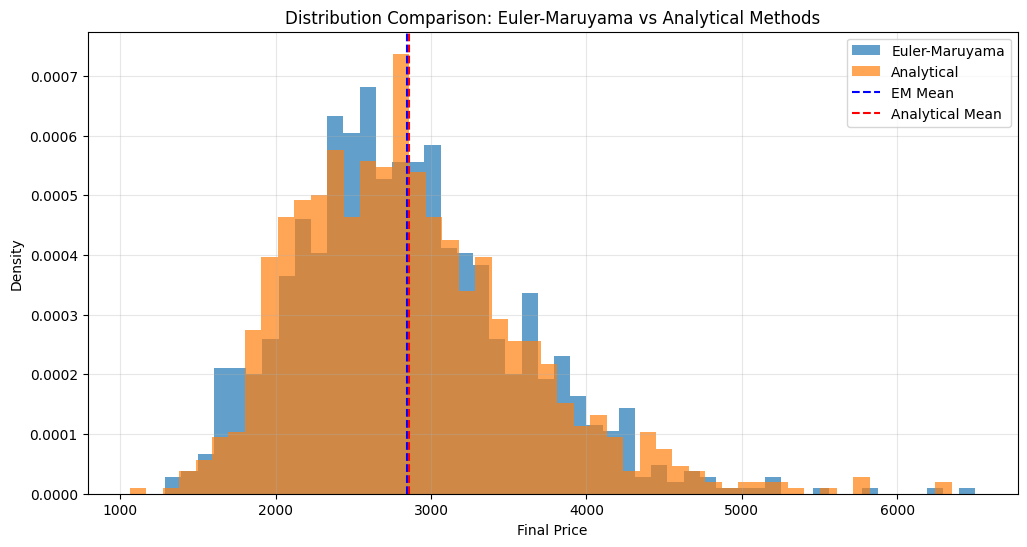


5. PERFORMING GOODNESS-OF-FIT TESTS...

--- Goodness-of-Fit Tests for BAJAJ ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0706, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 8311.6227, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9283, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.3227
  Kurtosis: 8.6292


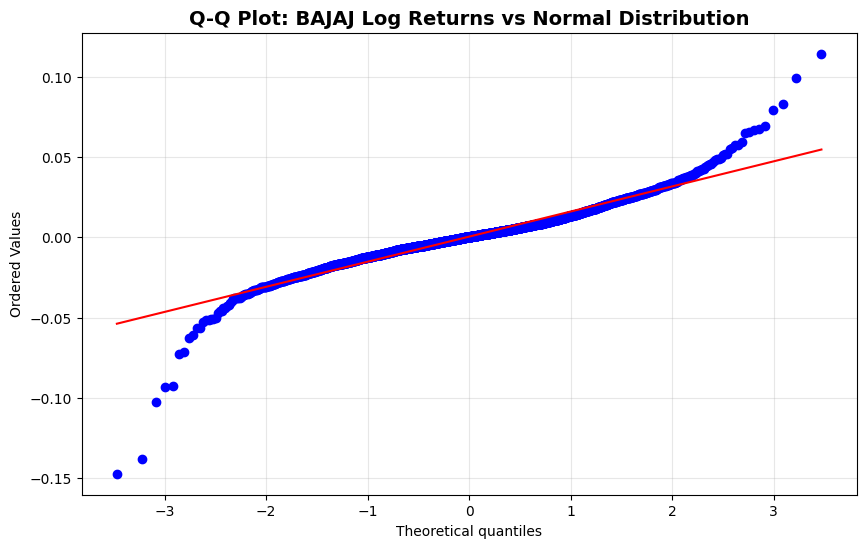


--- Goodness-of-Fit Tests for HDFCBank ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0716, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 12714.3880, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9092, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.3372
  Kurtosis: 10.6792


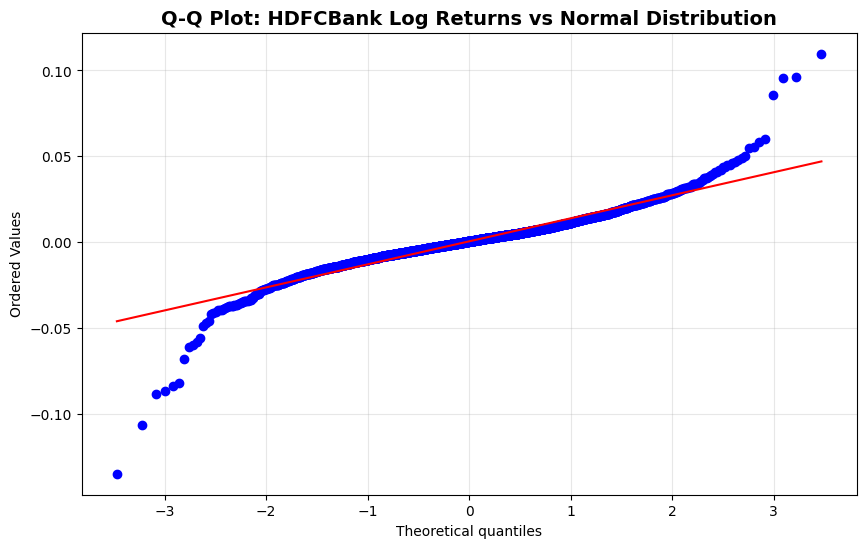


--- Goodness-of-Fit Tests for Hindalco ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0536, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 1653.4320, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9658, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.2013
  Kurtosis: 3.8384


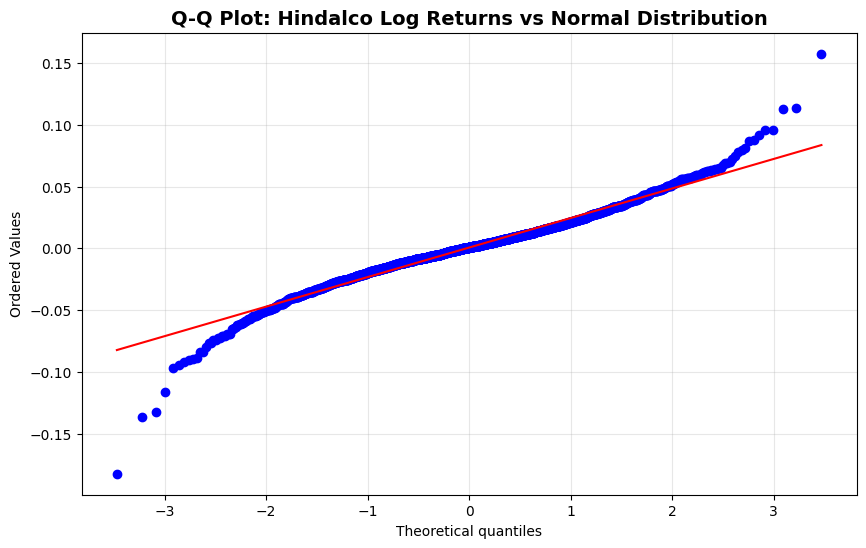


--- Goodness-of-Fit Tests for HUL ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0578, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 4974.2841, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9470, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.6406
  Kurtosis: 6.5705


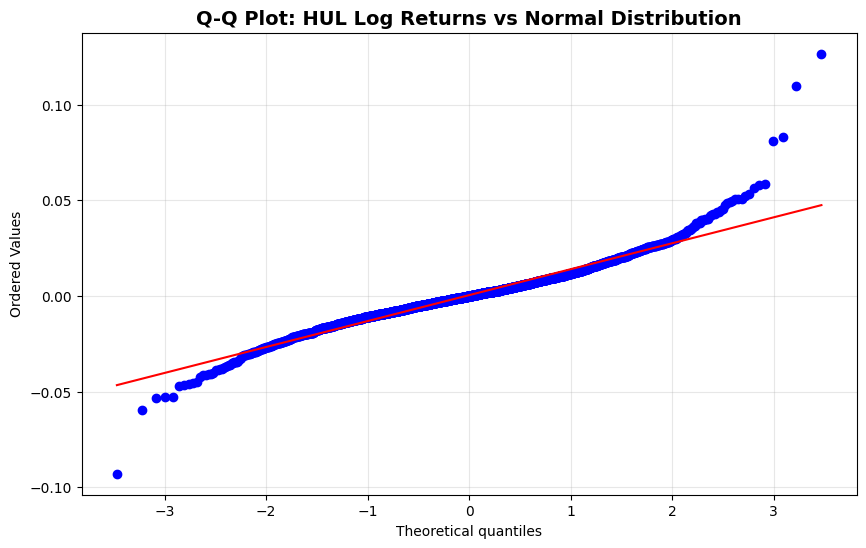


--- Goodness-of-Fit Tests for ICICIBank ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0715, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 9649.8743, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9187, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.1117
  Kurtosis: 9.3213


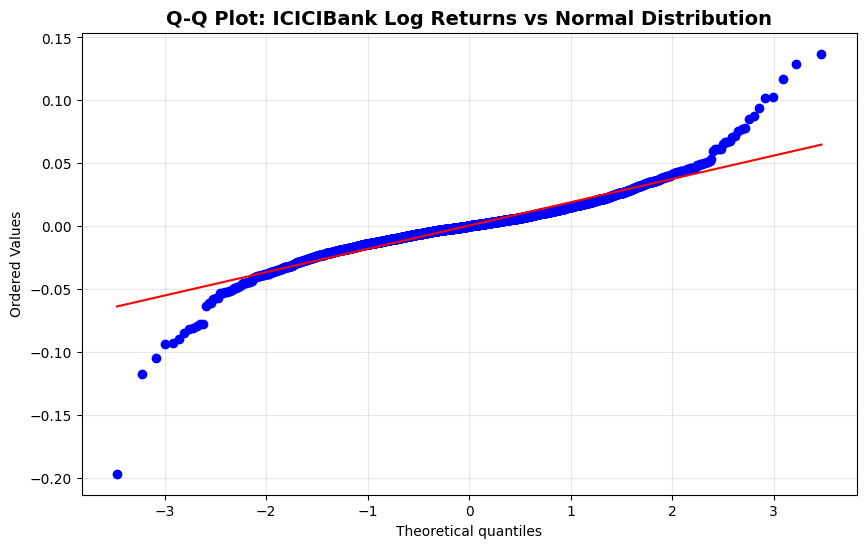


--- Goodness-of-Fit Tests for Infosys ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0591, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 11081.2100, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9228, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.5421
  Kurtosis: 9.9325


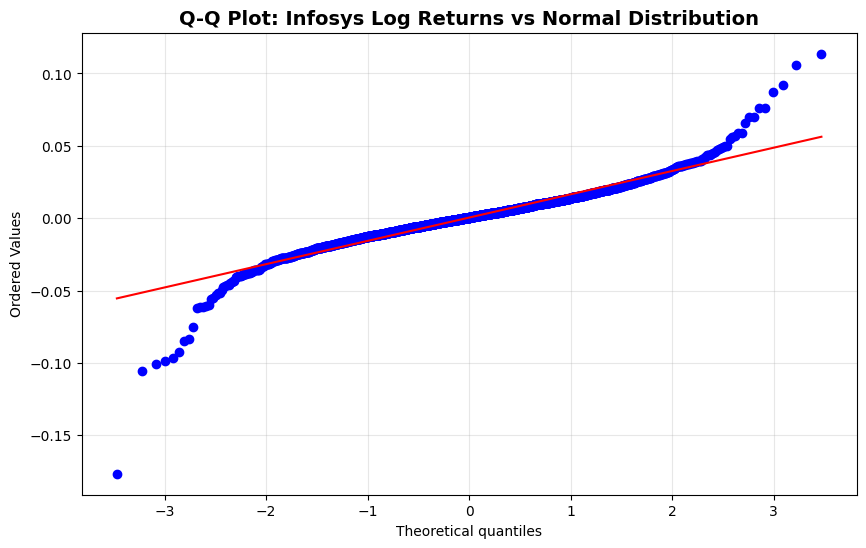


--- Goodness-of-Fit Tests for ITC ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0686, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 7558.4935, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9229, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.4537
  Kurtosis: 8.2003


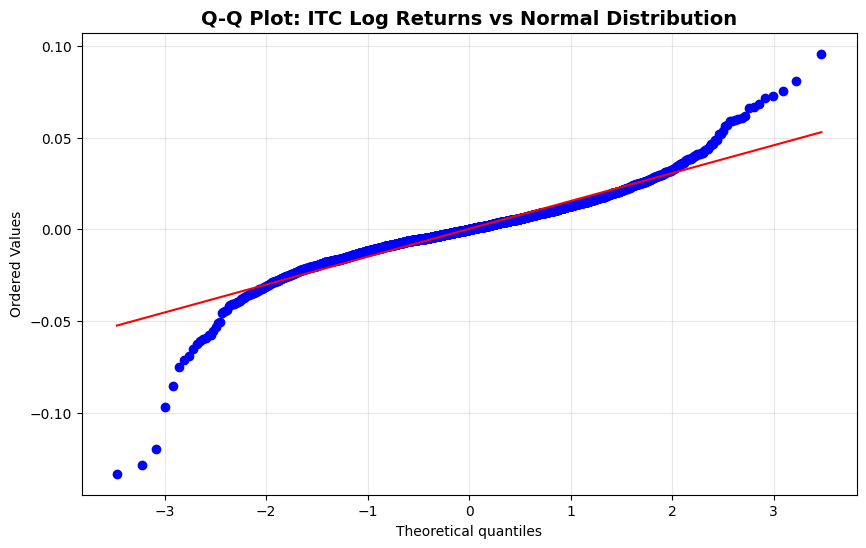


--- Goodness-of-Fit Tests for L&T ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0637, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 11335.2026, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9244, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.2167
  Kurtosis: 10.0961


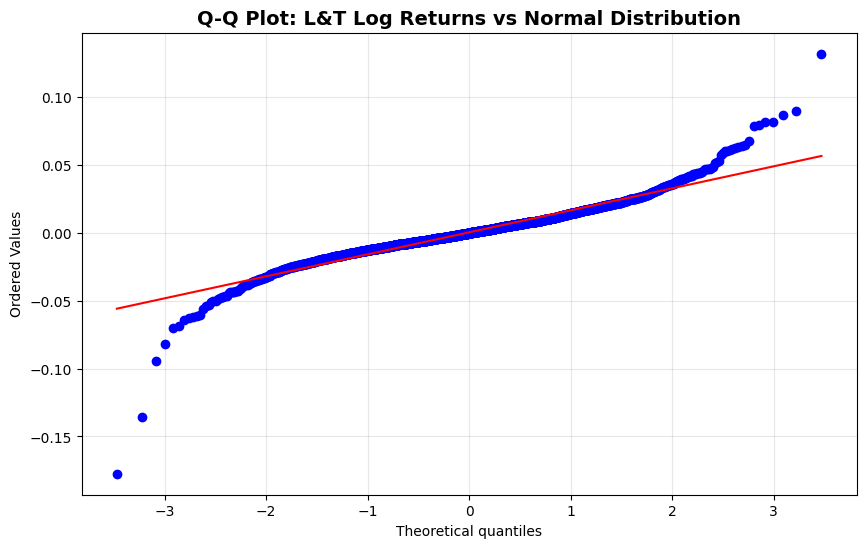


--- Goodness-of-Fit Tests for Nifty-50 ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0779, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 46632.1090, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.8808, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -1.3616
  Kurtosis: 20.3110


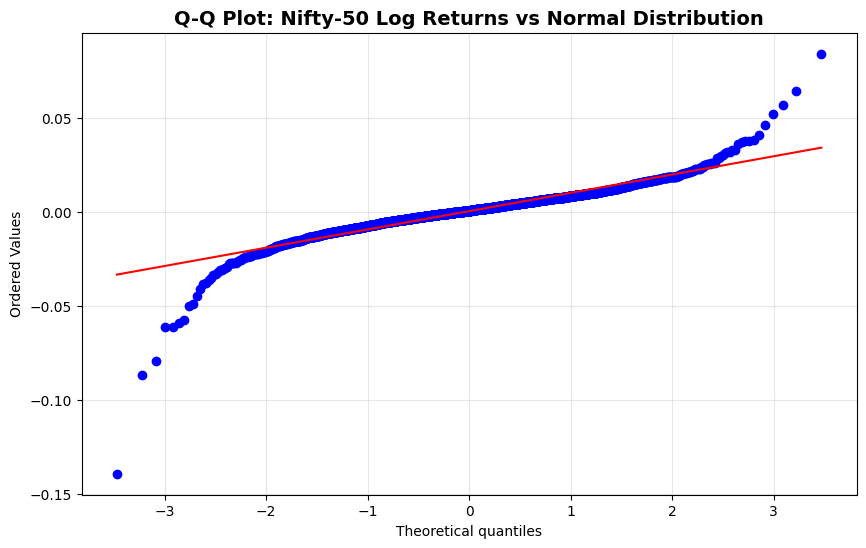


--- Goodness-of-Fit Tests for Reliance ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0567, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 7857.9964, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9272, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.0882
  Kurtosis: 8.4104


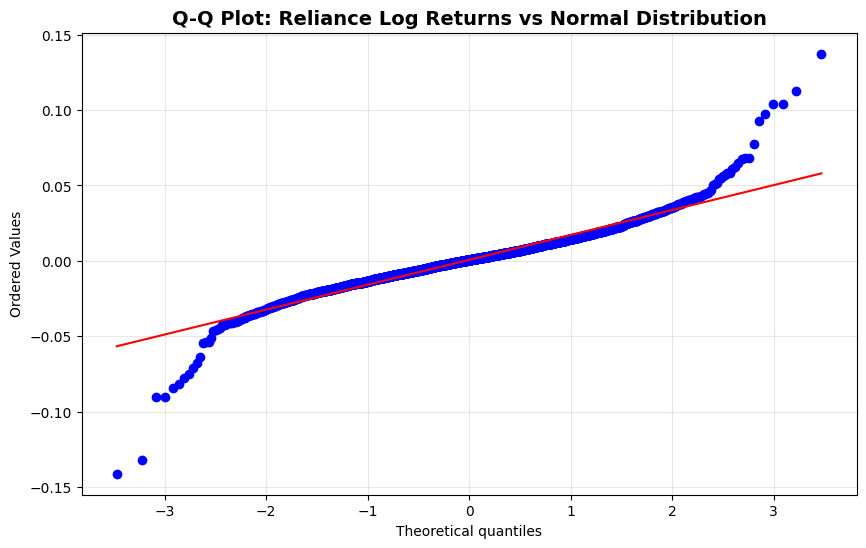


--- Goodness-of-Fit Tests for SBI ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0655, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 16931.7401, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9211, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.4490
  Kurtosis: 12.3156


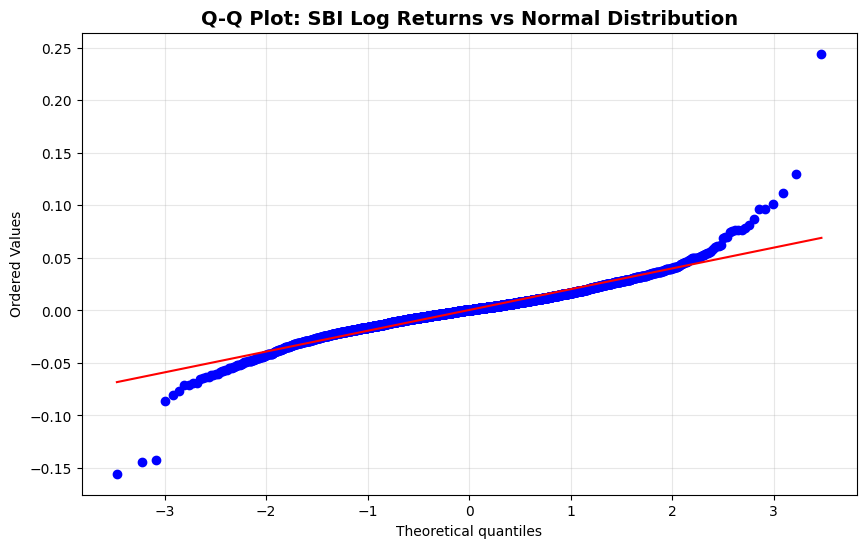


--- Goodness-of-Fit Tests for TATAMotors ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0698, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 5082.2727, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9287, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: 0.1510
  Kurtosis: 6.7598


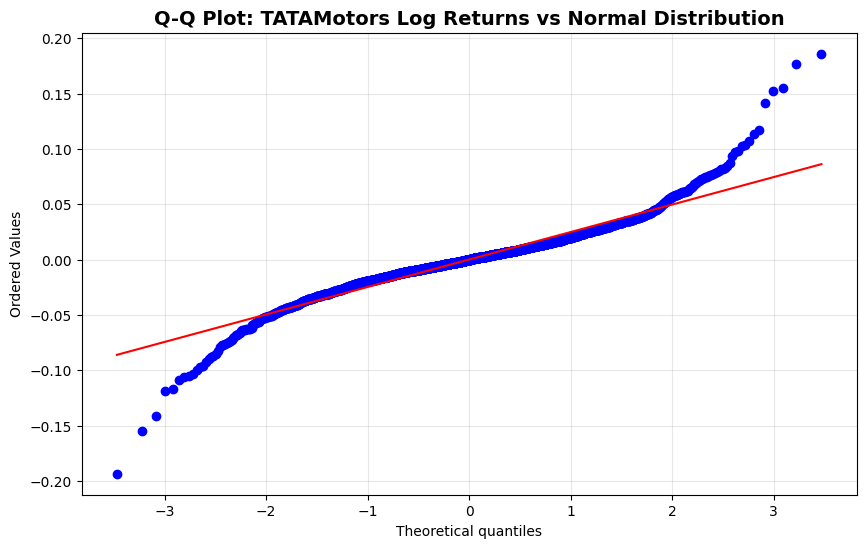


--- Goodness-of-Fit Tests for TataSteel ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0591, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 1251.4367, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9624, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.2044
  Kurtosis: 3.3321


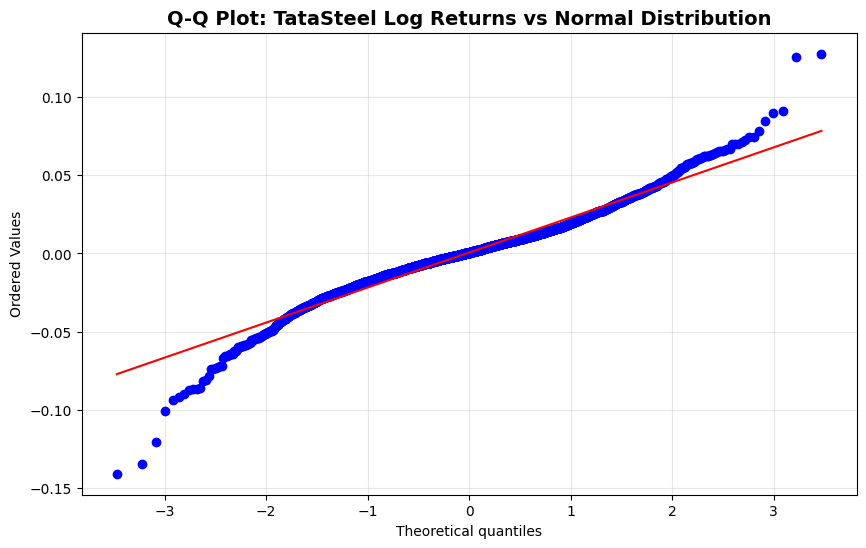


--- Goodness-of-Fit Tests for TCS ---
Kolmogorov-Smirnov Test:
  Statistic: 0.0547, p-value: 0.0000
  Reject normality: True
Jarque-Bera Test:
  Statistic: 1468.5517, p-value: 0.0000
  Reject normality: True
Shapiro-Wilk Test:
  Statistic: 0.9623, p-value: 0.0000
  Reject normality: True
Descriptive Statistics:
  Skewness: -0.0436
  Kurtosis: 3.6363


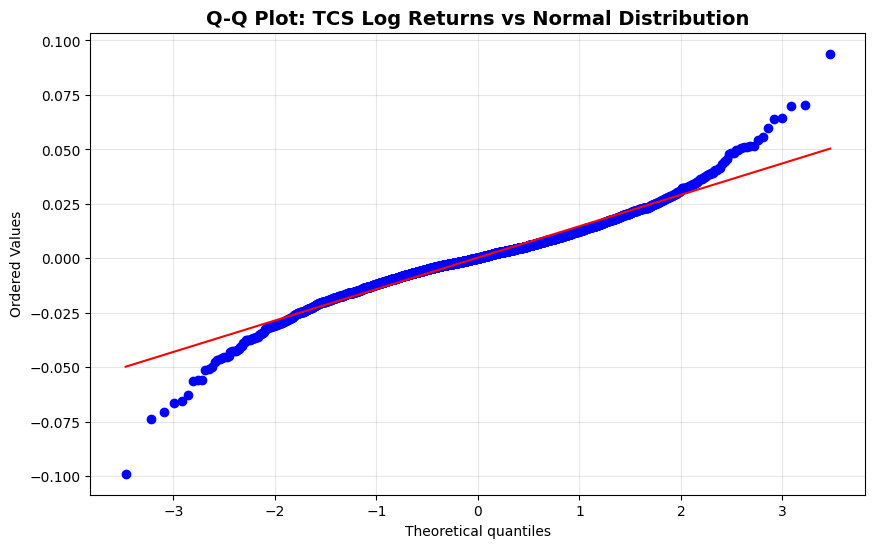


6. QUANTITATIVE LIMITATIONS ANALYSIS...


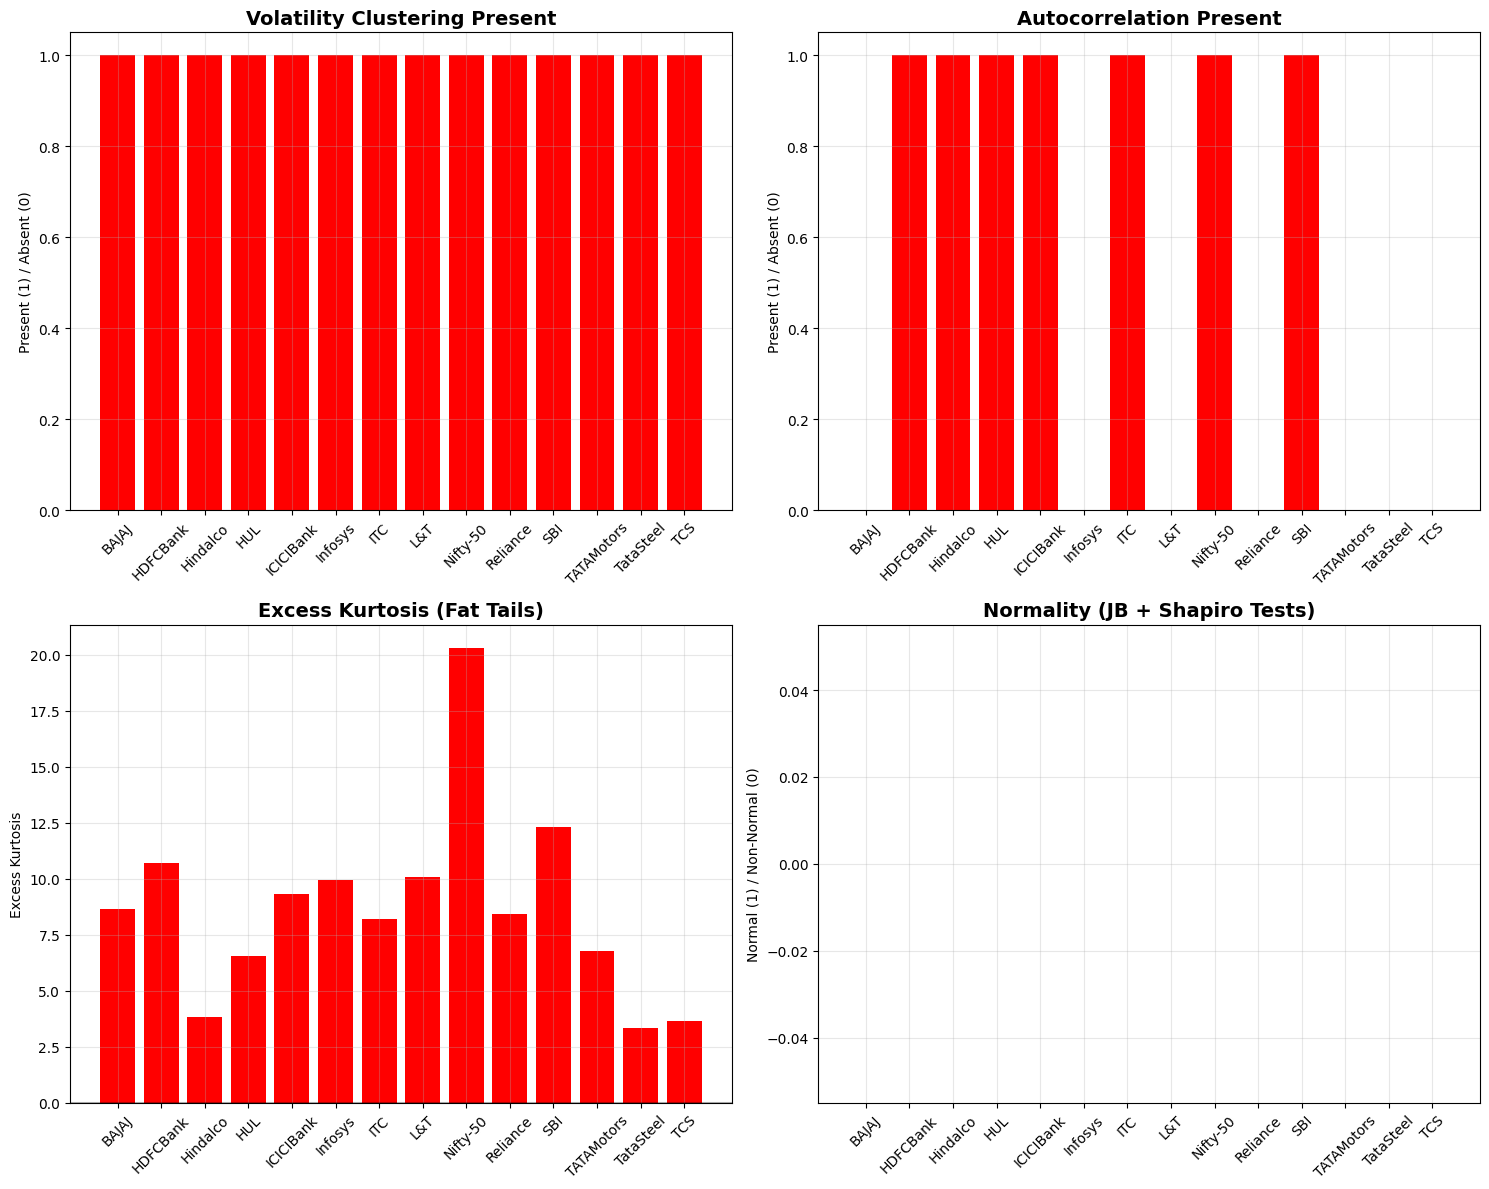


7. SIMULATION VALIDATION...

BAJAJ Simulation Validation:
  Actual mean return: 0.000475
  Simulated mean return: 0.120494
  Actual final price: 8679.50
  Simulated final price: 12355.52 ± 12697.50
  Price coverage (80-120%): 20.60%


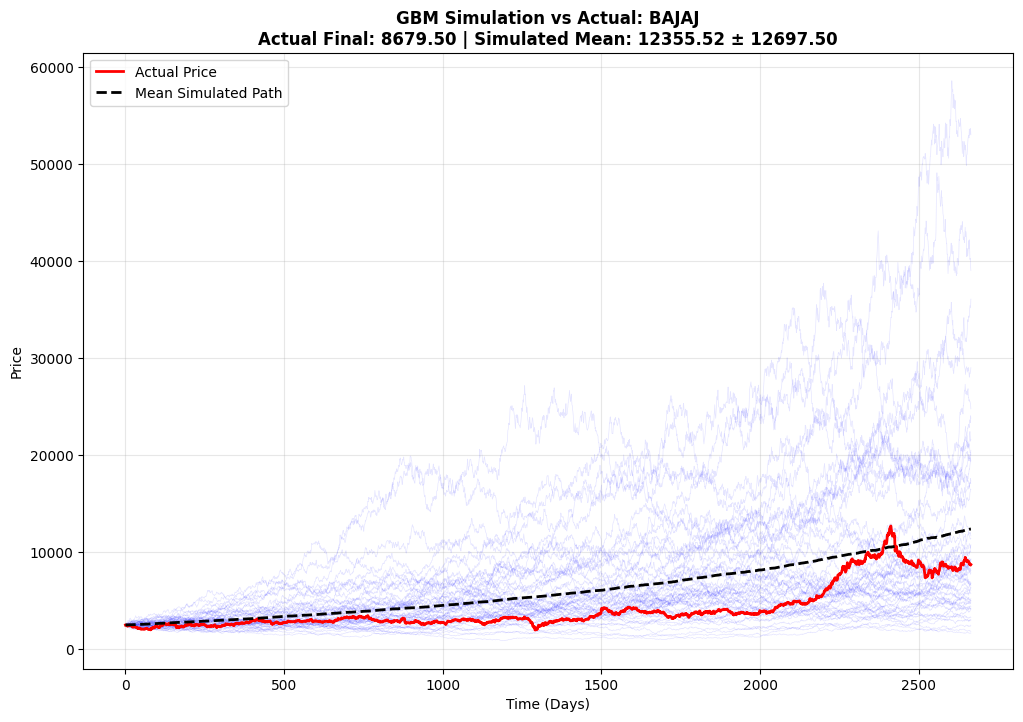


HDFCBank Simulation Validation:
  Actual mean return: 0.000522
  Simulated mean return: 0.131577
  Actual final price: 965.15
  Simulated final price: 1259.99 ± 1034.60
  Price coverage (80-120%): 22.90%


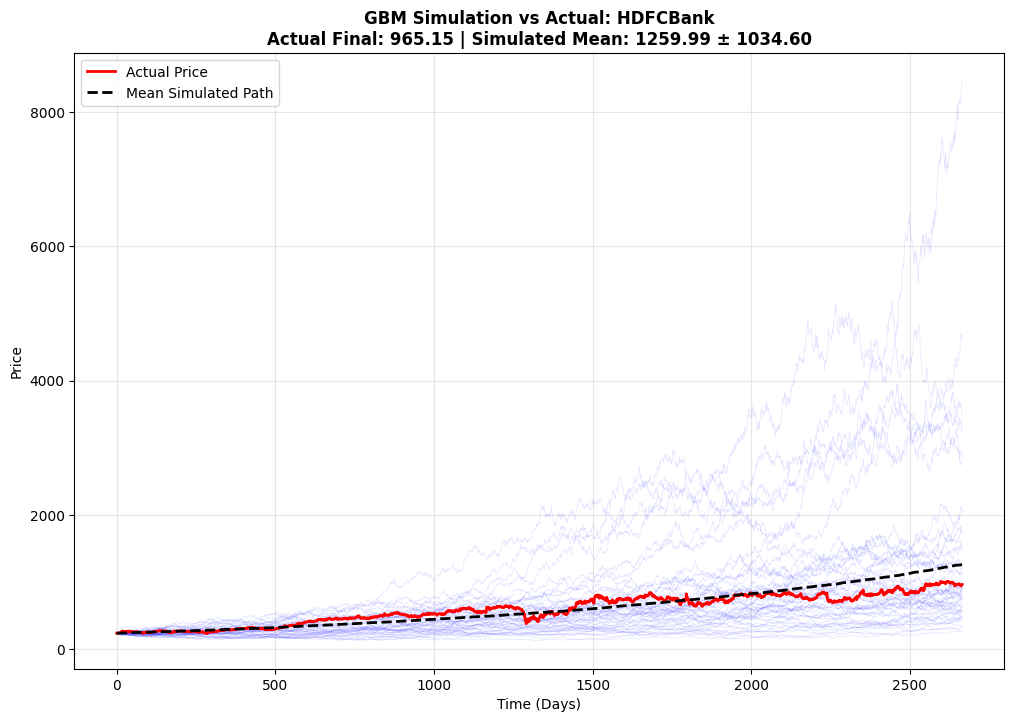


Hindalco Simulation Validation:
  Actual mean return: 0.000595
  Simulated mean return: 0.149879
  Actual final price: 780.35
  Simulated final price: 1830.47 ± 3630.86
  Price coverage (80-120%): 12.30%


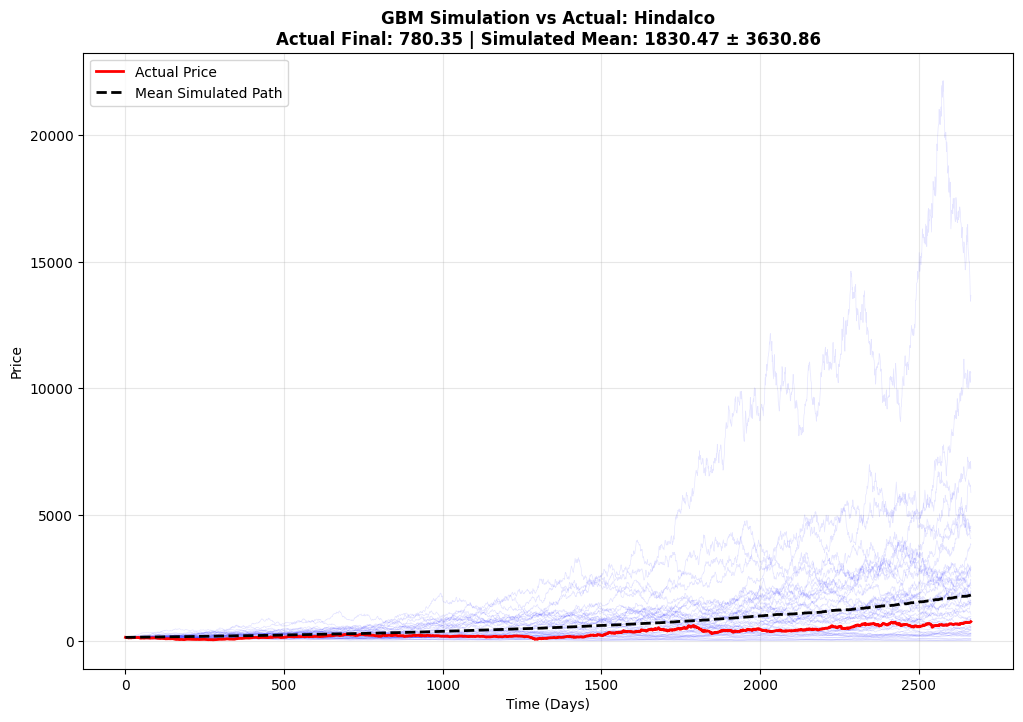


8. FORECAST EVALUATION...

--- Forecast Evaluation for BAJAJ ---
RMSE: 147.33
MAE: 98.60
MAPE: 1.17%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for HDFCBank ---
RMSE: 10.14
MAE: 7.24
MAPE: 0.87%
Training period: 2132 days
Testing period: 532 days

--- Forecast Evaluation for Hindalco ---
RMSE: 11.37
MAE: 7.97
MAPE: 1.29%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for HUL ---
RMSE: 29.03
MAE: 20.69
MAPE: 0.84%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for ICICIBank ---
RMSE: 13.99
MAE: 9.87
MAPE: 0.83%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for Infosys ---
RMSE: 24.35
MAE: 17.48
MAPE: 1.07%
Training period: 2131 days
Testing period: 532 days

--- Forecast Evaluation for ITC ---
RMSE: 5.70
MAE: 3.87
MAPE: 0.91%
Training period: 2132 days
Testing period: 532 days

--- Forecast Evaluation for L&T ---
RMSE: 55.36
MAE: 37.96
MAPE: 1.10%
Training period

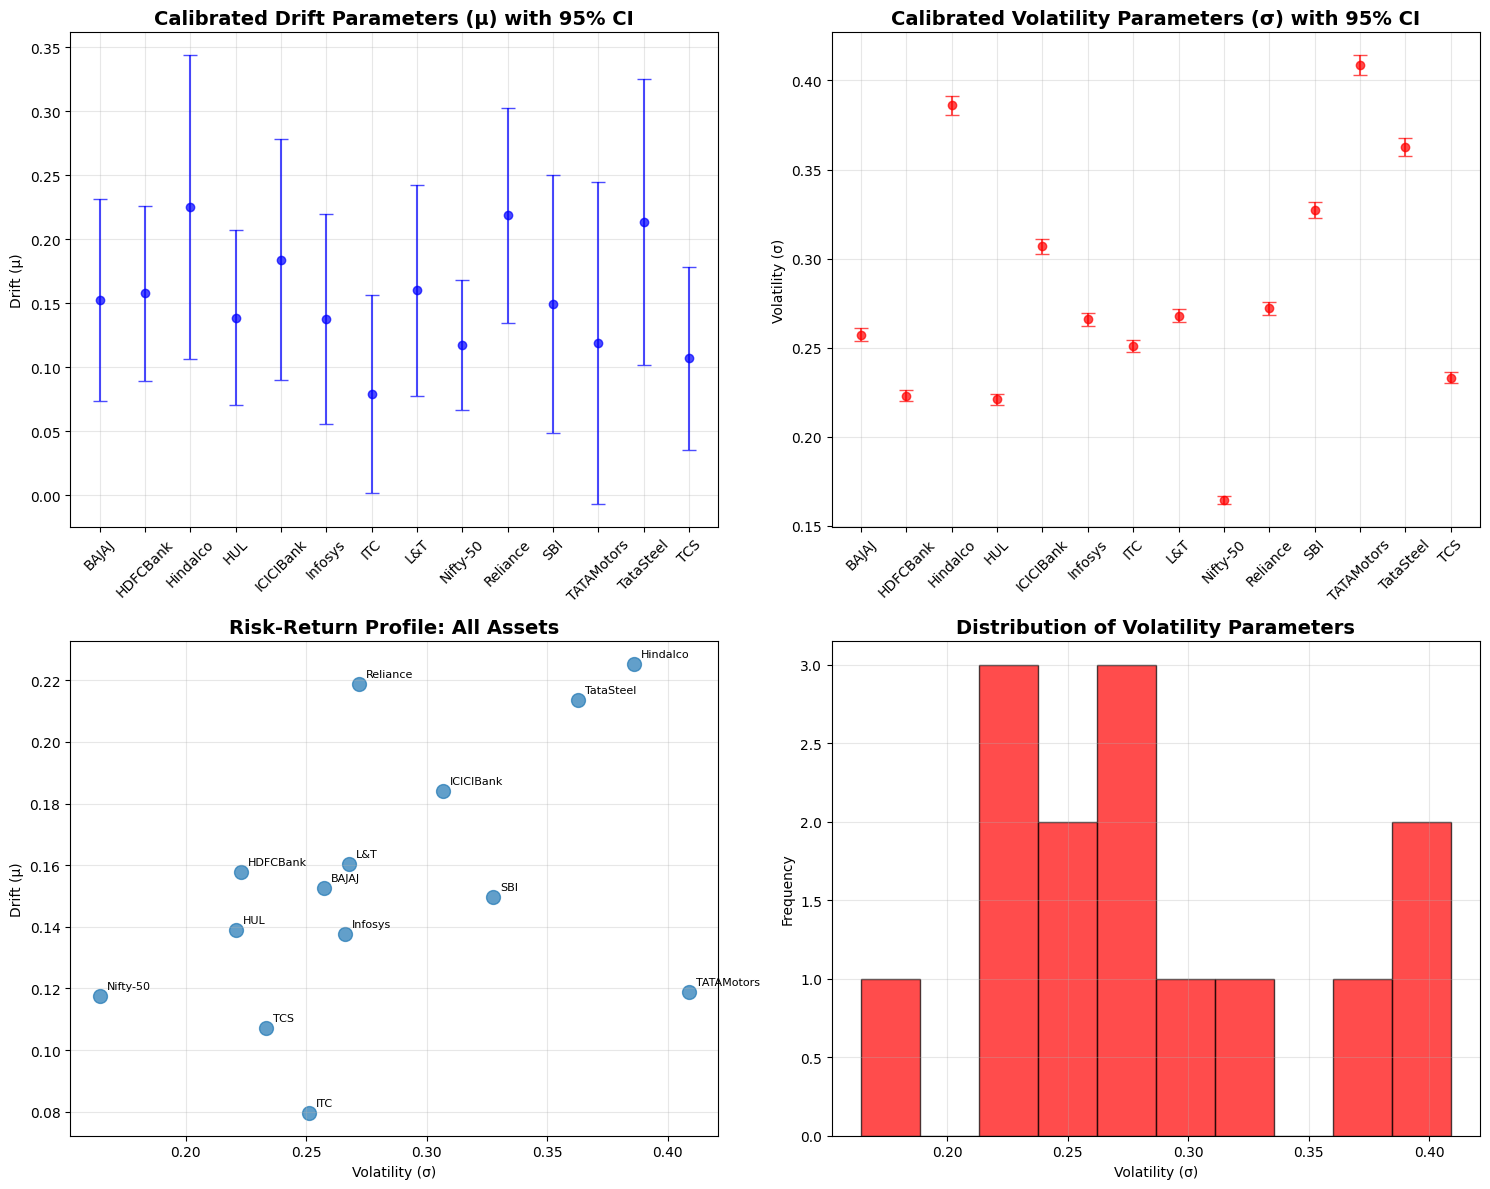

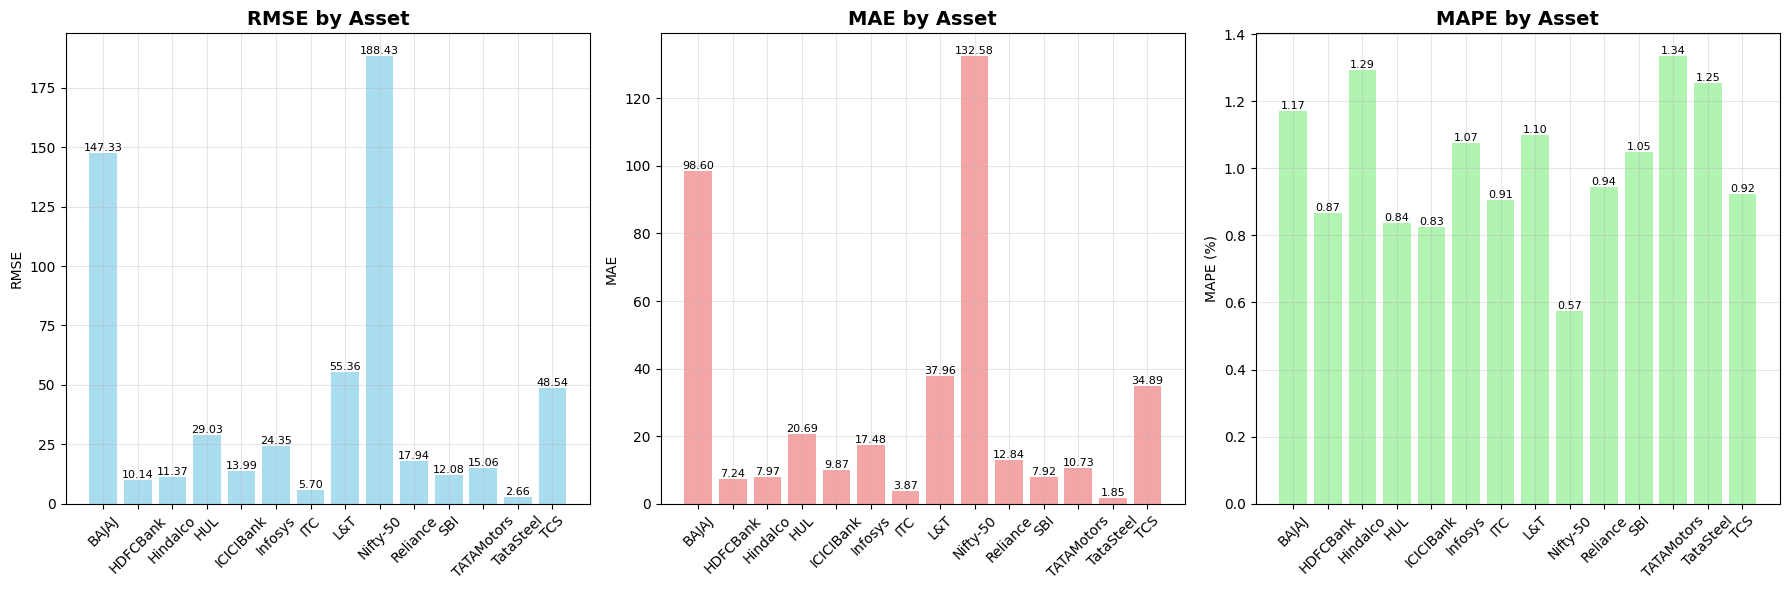

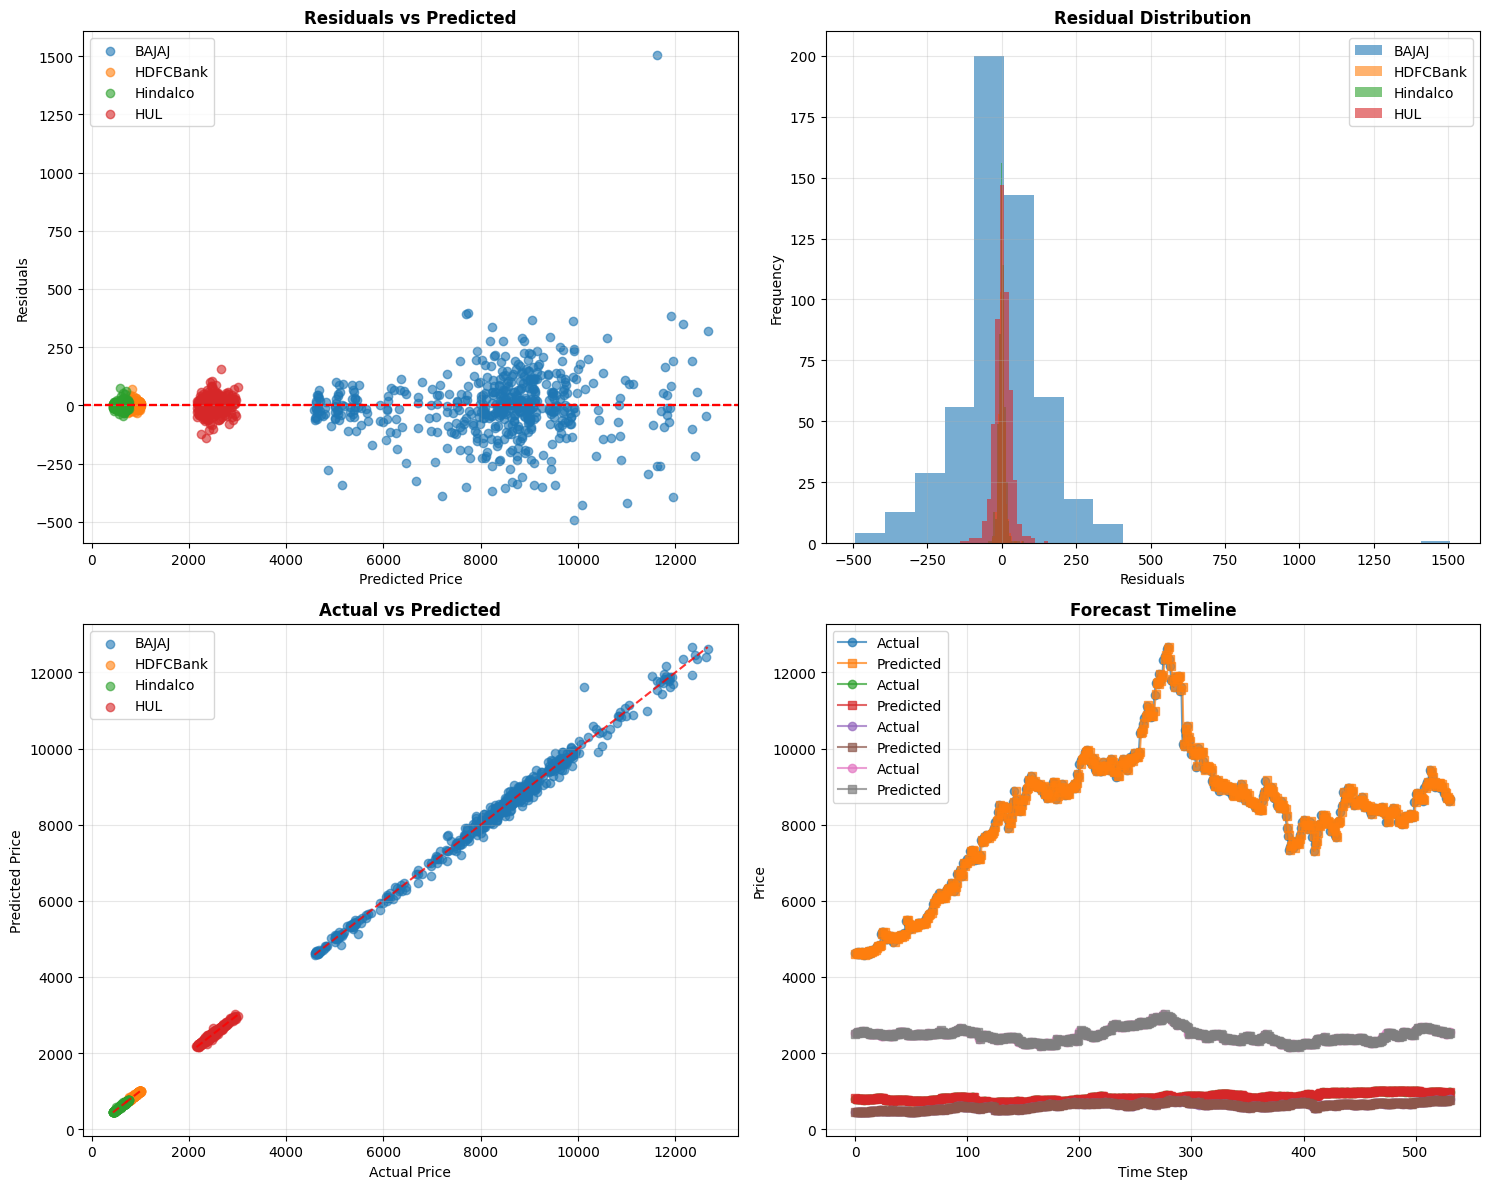


10. SAVING STRUCTURED RESULTS...

--- Saving Structured Results to ..\Data-Working\\GBM_Complete_Results ---
✓ Parameters saved to gbm_parameters.csv
✓ NIFTY parameters saved to nifty_parameters.csv
✓ Forecast metrics saved to forecast_metrics.csv
✓ Goodness-of-fit results saved to goodness_of_fit.csv
✓ GBM limitations analysis saved to gbm_limitations.csv
✓ Complete results saved to complete_results.json

11. GENERATING COMPREHENSIVE REPORT...
✓ Comprehensive report saved to: ..\Data-Working\\GBM_Complete_Results\gbm_comprehensive_analysis_report.txt

COMPLETE GBM ANALYSIS FINISHED SUCCESSFULLY!
All results saved to: ..\Data-Working\\GBM_Complete_Results

KEY FINDINGS SUMMARY
Average Forecast MAPE: 1.01%
Assets with volatility clustering: 14/14
Assets violating normality: 14/14
→ GBM forecasting accuracy: GOOD
→ Strong evidence of volatility clustering - consider GARCH models
→ Widespread normality violations - consider alternative distributions


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
from scipy.optimize import minimize
import warnings
from statsmodels.tsa.stattools import acf
import json

warnings.filterwarnings('ignore')

# =============================================================================
# STEP 1: ENHANCED GBM IMPLEMENTATION
# =============================================================================

class GBM:
    def __init__(self, mu, sigma, S0):
        self.mu = mu
        self.sigma = sigma
        self.S0 = S0
      
    def simulate_euler_maruyama(self, T, dt, n_paths):
        """
        Euler-Maruyama discretization scheme for GBM
        dS_t = μS_t dt + @S_t dW_t
        """
        n_steps = int(T / dt)
        time_points = np.linspace(0, T, n_steps + 1)
        
        # Initialize paths
        paths = np.zeros((n_steps + 1, n_paths))
        paths[0] = self.S0
        
        # Brownian increments
        dW = np.random.normal(0, np.sqrt(dt), (n_steps, n_paths))
        
        # Euler-Maruyama scheme
        for t in range(1, n_steps + 1):
            paths[t] = paths[t-1] * (1 + self.mu * dt + self.sigma * dW[t-1])
        
        return time_points, paths
    
    def simulate_analytical(self, T, dt, n_paths):
        """
        Analytical solution for GBM using log-normal property
        S_t = S_0 * exp((μ - σ²/2)t + @W_t)
        """
        n_steps = int(T / dt)
        time_points = np.linspace(0, T, n_steps + 1)
        
        # Brownian motion
        W = np.zeros((n_steps + 1, n_paths))
        dW = np.random.normal(0, np.sqrt(dt), (n_steps, n_paths))
        
        # Cumulative Brownian motion
        for t in range(1, n_steps + 1):
            W[t] = W[t-1] + dW[t-1]
        
        # Analytical solution
        paths = self.S0 * np.exp((self.mu - 0.5 * self.sigma**2) * time_points.reshape(-1, 1) 
                               + self.sigma * W)
        
        return time_points, paths

class GBMCalibrator:
    """
    MLE Calibration for Geometric Brownian Motion
    """
    
    @staticmethod
    def mle_closed_form(log_returns, dt):
        """
        Closed-form MLE estimators for GBM parameters
        """
        n = len(log_returns)
        
        # MLE for volatility (annualized)
        sigma_hat = np.std(log_returns) / np.sqrt(dt)
        
        # MLE for drift (annualized) - WITH convexity adjustment
        mu_hat = (np.mean(log_returns) / dt) + 0.5 * sigma_hat**2
        
        return mu_hat, sigma_hat
    
    @staticmethod
    def compute_confidence_intervals(log_returns, dt, alpha=0.05):
        """
        Compute confidence intervals using Fisher Information
        """
        n = len(log_returns)
        mu_hat, sigma_hat = GBMCalibrator.mle_closed_form(log_returns, dt)
        
        # Fisher Information matrix
        I_mu = n * dt / (sigma_hat**2)
        I_sigma = 2 * n / (sigma_hat**2)
        
        # Standard errors
        se_mu = 1 / np.sqrt(I_mu)
        se_sigma = 1 / np.sqrt(I_sigma)
        
        # Critical value (z-score for normal)
        z = stats.norm.ppf(1 - alpha/2)
        
        # Confidence intervals
        ci_mu = (mu_hat - z * se_mu, mu_hat + z * se_mu)
        ci_sigma = (sigma_hat - z * se_sigma, sigma_hat + z * se_sigma)
        
        return {
            'mu_ci': ci_mu,
            'sigma_ci': ci_sigma,
            'se_mu': se_mu,
            'se_sigma': se_sigma
        }

# =============================================================================
# STEP 2: COMPREHENSIVE GBM VALIDATION & TESTING
# =============================================================================

class GBMValidator:
    """
    Comprehensive validation of GBM model assumptions and performance
    """
    
    @staticmethod
    def compare_simulation_methods(gbm_model, T, dt, n_paths=1000):
        """
        Compare Euler-Maruyama vs Analytical simulation methods
        """
        print(f"\n--- Simulation Method Comparison ---")
        
        # Euler-Maruyama simulation
        time_em, paths_em = gbm_model.simulate_euler_maruyama(T, dt, n_paths)
        
        # Analytical simulation  
        time_an, paths_an = gbm_model.simulate_analytical(T, dt, n_paths)
        
        # Compare statistics
        final_prices_em = paths_em[-1]
        final_prices_an = paths_an[-1]
        
        comparison = {
            'em_mean': np.mean(final_prices_em),
            'em_std': np.std(final_prices_em),
            'an_mean': np.mean(final_prices_an), 
            'an_std': np.std(final_prices_an),
            'mean_diff': np.abs(np.mean(final_prices_em) - np.mean(final_prices_an)),
            'std_diff': np.abs(np.std(final_prices_em) - np.std(final_prices_an)),
            'mean_diff_pct': np.abs(np.mean(final_prices_em) - np.mean(final_prices_an)) / np.mean(final_prices_an) * 100,
            'std_diff_pct': np.abs(np.std(final_prices_em) - np.std(final_prices_an)) / np.std(final_prices_an) * 100
        }
        
        print(f"Euler-Maruyama - Mean: {comparison['em_mean']:.2f}, Std: {comparison['em_std']:.2f}")
        print(f"Analytical     - Mean: {comparison['an_mean']:.2f}, Std: {comparison['an_std']:.2f}")
        print(f"Difference     - Mean: {comparison['mean_diff_pct']:.2f}%, Std: {comparison['std_diff_pct']:.2f}%")
        
        # Plot comparison
        plt.figure(figsize=(12, 6))
        plt.hist(final_prices_em, bins=50, alpha=0.7, label='Euler-Maruyama', density=True)
        plt.hist(final_prices_an, bins=50, alpha=0.7, label='Analytical', density=True)
        plt.axvline(comparison['em_mean'], color='blue', linestyle='--', label='EM Mean')
        plt.axvline(comparison['an_mean'], color='red', linestyle='--', label='Analytical Mean')
        plt.xlabel('Final Price')
        plt.ylabel('Density')
        plt.title('Distribution Comparison: Euler-Maruyama vs Analytical Methods')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()
        
        return comparison
    
    @staticmethod
    def goodness_of_fit_tests(log_returns, asset_name, alpha=0.05):
        """
        Perform statistical tests for normality assumption
        """
        print(f"\n--- Goodness-of-Fit Tests for {asset_name} ---")
        
        results = {}
        
        # 1. Kolmogorov-Smirnov test for normality
        ks_stat, ks_pvalue = stats.kstest(log_returns, 'norm', 
                                         args=(np.mean(log_returns), np.std(log_returns)))
        results['ks_test'] = {
            'statistic': ks_stat,
            'p_value': ks_pvalue,
            'reject_normal': ks_pvalue < alpha
        }
        print(f"Kolmogorov-Smirnov Test:")
        print(f"  Statistic: {ks_stat:.4f}, p-value: {ks_pvalue:.4f}")
        print(f"  Reject normality: {ks_pvalue < alpha}")
        
        # 2. Jarque-Bera test for normality
        jb_stat, jb_pvalue = stats.jarque_bera(log_returns)
        results['jb_test'] = {
            'statistic': jb_stat,
            'p_value': jb_pvalue,
            'reject_normal': jb_pvalue < alpha
        }
        print(f"Jarque-Bera Test:")
        print(f"  Statistic: {jb_stat:.4f}, p-value: {jb_pvalue:.4f}")
        print(f"  Reject normality: {jb_pvalue < alpha}")
        
        # 3. Shapiro-Wilk test (additional normality test)
        shapiro_stat, shapiro_pvalue = stats.shapiro(log_returns)
        results['shapiro_test'] = {
            'statistic': shapiro_stat,
            'p_value': shapiro_pvalue,
            'reject_normal': shapiro_pvalue < alpha
        }
        print(f"Shapiro-Wilk Test:")
        print(f"  Statistic: {shapiro_stat:.4f}, p-value: {shapiro_pvalue:.4f}")
        print(f"  Reject normality: {shapiro_pvalue < alpha}")
        
        # 4. Additional statistics
        results['descriptive_stats'] = {
            'skewness': stats.skew(log_returns),
            'kurtosis': stats.kurtosis(log_returns),
            'mean': np.mean(log_returns),
            'std': np.std(log_returns)
        }
        print(f"Descriptive Statistics:")
        print(f"  Skewness: {results['descriptive_stats']['skewness']:.4f}")
        print(f"  Kurtosis: {results['descriptive_stats']['kurtosis']:.4f}")
        
        return results
    
    @staticmethod
    def plot_qq(log_returns, asset_name, save_path=None):
        """
        Create QQ-plot for visual normality assessment
        """
        plt.figure(figsize=(10, 6))
        
        # Create QQ plot
        stats.probplot(log_returns, dist="norm", plot=plt)
        plt.title(f'Q-Q Plot: {asset_name} Log Returns vs Normal Distribution', 
                 fontsize=14, fontweight='bold')
        plt.grid(True, alpha=0.3)
        
        if save_path:
            plt.savefig(os.path.join(save_path, f'qq_plot_{asset_name}.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def simulation_validation(gbm_model, actual_prices, T, dt, n_paths=1000):
        """
        Compare simulated paths with actual data
        """
        # Simulate paths using analytical method (more accurate)
        time_points, simulated_paths = gbm_model.simulate_analytical(T, dt, n_paths)
        
        # Calculate actual and simulated returns
        actual_returns = np.diff(np.log(actual_prices))
        simulated_final_returns = np.log(simulated_paths[-1] / gbm_model.S0)
        
        # Statistical comparison
        comparison = {
            'actual_mean_return': np.mean(actual_returns),
            'simulated_mean_return': np.mean(simulated_final_returns) / T,
            'actual_std_return': np.std(actual_returns),
            'simulated_std_return': np.std(simulated_final_returns) / np.sqrt(T),
            'actual_final_price': actual_prices[-1],
            'simulated_final_price_mean': np.mean(simulated_paths[-1]),
            'simulated_final_price_std': np.std(simulated_paths[-1]),
            'price_coverage': np.mean((simulated_paths[-1] >= actual_prices[-1] * 0.8) & 
                                     (simulated_paths[-1] <= actual_prices[-1] * 1.2))
        }
        
        return time_points, simulated_paths, comparison
    
    @staticmethod
    def forecast_evaluation(data_dict, parameters, train_ratio=0.8):
        """
        Perform 1-day ahead forecasting and compute error metrics
        """
        forecast_results = {}
        dt_daily = 1/252
        
        for asset_name, df in data_dict.items():
            print(f"\n--- Forecast Evaluation for {asset_name} ---")
            
            # Split data into training and testing
            n_train = int(len(df) * train_ratio)
            train_data = df.iloc[:n_train]
            test_data = df.iloc[n_train:]
            
            # Recalibrate on training data only
            train_returns = train_data['LOG'].values
            mu_train, sigma_train = GBMCalibrator.mle_closed_form(train_returns, dt_daily)
            S0_test = test_data['Price'].iloc[0]
            
            # Create GBM model with training parameters
            gbm = GBM(mu_train, sigma_train, S0_test)
            
            # 1-day ahead predictions
            actual_prices = test_data['Price'].values
            n_test = len(actual_prices) - 1
            
            predicted_prices = []
            actual_next_prices = []
            
            current_price = S0_test
            for i in range(n_test):
                # Simulate one day ahead
                _, one_day_path = gbm.simulate_analytical(1/252, 1/252, 1000)
                predicted_price = np.mean(one_day_path[-1])
                predicted_prices.append(predicted_price)
                actual_next_prices.append(actual_prices[i+1])
                
                # Update current price for next prediction (rolling forecast)
                current_price = actual_prices[i+1]
                gbm.S0 = current_price
            
            predicted_prices = np.array(predicted_prices)
            actual_next_prices = np.array(actual_next_prices)
            
            # Calculate error metrics
            mse = np.mean((predicted_prices - actual_next_prices) ** 2)
            rmse = np.sqrt(mse)
            mae = np.mean(np.abs(predicted_prices - actual_next_prices))
            mape = np.mean(np.abs((predicted_prices - actual_next_prices) / actual_next_prices)) * 100
            
            forecast_results[asset_name] = {
                'rmse': rmse,
                'mae': mae,
                'mape': mape,
                'mse': mse,
                'predicted_prices': predicted_prices,
                'actual_prices': actual_next_prices,
                'train_size': n_train,
                'test_size': n_test
            }
            
            print(f"RMSE: {rmse:.2f}")
            print(f"MAE: {mae:.2f}")
            print(f"MAPE: {mape:.2f}%")
            print(f"Training period: {n_train} days")
            print(f"Testing period: {n_test} days")
        
        return forecast_results

    @staticmethod
    def analyze_limitations(data_dict, parameters, alpha=0.05):
        """
        Quantitative analysis of GBM limitations
        """
        limitations = {}
        
        for asset_name, df in data_dict.items():
            returns = df['LOG'].values
            
            # 1. Volatility clustering test (ARCH effects)
            squared_returns = returns**2
            acf_squared = acf(squared_returns, nlags=5, fft=False)
            
            # Test if any ACF of squared returns is significant
            vol_clustering_present = any(np.abs(acf_squared[1:]) > 1.96/np.sqrt(len(returns)))
            
            # 2. Autocorrelation test
            acf_returns = acf(returns, nlags=5, fft=False)
            autocorrelation_present = any(np.abs(acf_returns[1:]) > 1.96/np.sqrt(len(returns)))
            
            # 3. Fat tails analysis
            excess_kurtosis = stats.kurtosis(returns, fisher=False)  # Pearson's definition (normal=3)
            
            # 4. Normality test summary
            is_normal = (stats.jarque_bera(returns)[1] > alpha and 
                        stats.shapiro(returns)[1] > alpha)
            
            limitations[asset_name] = {
                'vol_clustering_present': vol_clustering_present,
                'autocorrelation_present': autocorrelation_present,
                'excess_kurtosis': excess_kurtosis - 3,  # Excess over normal
                'is_normal': is_normal,
                'acf_squared': acf_squared[1:],  # Significant ACF in squared returns
                'acf_returns': acf_returns[1:],  # Significant ACF in returns
                'n_obs': len(returns)
            }
        
        return limitations

# =============================================================================
# STEP 3: COMPREHENSIVE VISUALIZATION & REPORTING
# =============================================================================

class GBMVisualizer:
    """
    Create comprehensive visualizations for GBM analysis
    """
    
    @staticmethod
    def plot_calibration_summary(parameters):
        """
        Enhanced calibration results visualization
        """
        assets = list(parameters.keys())
        mu_values = [parameters[asset]['mu'] for asset in assets]
        sigma_values = [parameters[asset]['sigma'] for asset in assets]
        mu_errors = [parameters[asset]['se_mu'] for asset in assets]
        sigma_errors = [parameters[asset]['se_sigma'] for asset in assets]
        
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
        
        # Plot 1: Mu with confidence intervals
        ax1.errorbar(range(len(assets)), mu_values, yerr=mu_errors, fmt='o', 
                    capsize=5, color='blue', alpha=0.7)
        ax1.set_title('Calibrated Drift Parameters (μ) with 95% CI', 
                     fontsize=14, fontweight='bold')
        ax1.set_ylabel('Drift (μ)')
        ax1.set_xticks(range(len(assets)))
        ax1.set_xticklabels(assets, rotation=45)
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Sigma with confidence intervals
        ax2.errorbar(range(len(assets)), sigma_values, yerr=sigma_errors, fmt='o', 
                    capsize=5, color='red', alpha=0.7)
        ax2.set_title('Calibrated Volatility Parameters (σ) with 95% CI', 
                     fontsize=14, fontweight='bold')
        ax2.set_ylabel('Volatility (σ)')
        ax2.set_xticks(range(len(assets)))
        ax2.set_xticklabels(assets, rotation=45)
        ax2.grid(True, alpha=0.3)
        
        # Plot 3: Risk-Return scatter
        ax3.scatter(sigma_values, mu_values, s=100, alpha=0.7)
        for i, asset in enumerate(assets):
            ax3.annotate(asset, (sigma_values[i], mu_values[i]), 
                        xytext=(5, 5), textcoords='offset points', fontsize=8)
        ax3.set_xlabel('Volatility (σ)')
        ax3.set_ylabel('Drift (μ)')
        ax3.set_title('Risk-Return Profile: All Assets', fontsize=14, fontweight='bold')
        ax3.grid(True, alpha=0.3)
        
        # Plot 4: Parameter distribution
        ax4.hist(sigma_values, bins=10, alpha=0.7, color='red', edgecolor='black')
        ax4.set_xlabel('Volatility (σ)')
        ax4.set_ylabel('Frequency')
        ax4.set_title('Distribution of Volatility Parameters', 
                     fontsize=14, fontweight='bold')
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig('gbm_comprehensive_calibration.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_simulation_vs_actual(asset_name, actual_prices, time_points, 
                                simulated_paths, comparison, save_path=None):
        """
        Plot simulated paths vs actual price trajectory
        """
        plt.figure(figsize=(12, 8))
        
        # Plot simulated paths (first 50 for clarity)
        n_paths_to_plot = min(50, simulated_paths.shape[1])
        for i in range(n_paths_to_plot):
            plt.plot(time_points * 252, simulated_paths[:, i], 
                    alpha=0.1, color='blue', linewidth=0.5)
        
        # Plot actual price trajectory
        actual_time = np.linspace(0, time_points[-1], len(actual_prices)) * 252
        plt.plot(actual_time, actual_prices, 'r-', linewidth=2, label='Actual Price')
        
        # Plot mean simulated path
        mean_path = np.mean(simulated_paths, axis=1)
        plt.plot(time_points * 252, mean_path, 'k--', linewidth=2, 
                label='Mean Simulated Path')
        
        plt.xlabel('Time (Days)')
        plt.ylabel('Price')
        plt.title(f'GBM Simulation vs Actual: {asset_name}\n'
                 f'Actual Final: {comparison["actual_final_price"]:.2f} | '
                 f'Simulated Mean: {comparison["simulated_final_price_mean"]:.2f} ± '
                 f'{comparison["simulated_final_price_std"]:.2f}',
                 fontsize=12, fontweight='bold')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        if save_path:
            plt.savefig(os.path.join(save_path, f'simulation_vs_actual_{asset_name}.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_forecast_results(forecast_results, save_path=None):
        """
        Plot forecasting performance across assets
        """
        assets = list(forecast_results.keys())
        rmse_values = [forecast_results[asset]['rmse'] for asset in assets]
        mae_values = [forecast_results[asset]['mae'] for asset in assets]
        mape_values = [forecast_results[asset]['mape'] for asset in assets]
        
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
        
        # RMSE
        bars1 = ax1.bar(assets, rmse_values, color='skyblue', alpha=0.7)
        ax1.set_title('RMSE by Asset', fontsize=14, fontweight='bold')
        ax1.set_ylabel('RMSE')
        ax1.tick_params(axis='x', rotation=45)
        ax1.grid(True, alpha=0.3)
        
        # MAE
        bars2 = ax2.bar(assets, mae_values, color='lightcoral', alpha=0.7)
        ax2.set_title('MAE by Asset', fontsize=14, fontweight='bold')
        ax2.set_ylabel('MAE')
        ax2.tick_params(axis='x', rotation=45)
        ax2.grid(True, alpha=0.3)
        
        # MAPE
        bars3 = ax3.bar(assets, mape_values, color='lightgreen', alpha=0.7)
        ax3.set_title('MAPE by Asset', fontsize=14, fontweight='bold')
        ax3.set_ylabel('MAPE (%)')
        ax3.tick_params(axis='x', rotation=45)
        ax3.grid(True, alpha=0.3)
        
        # Add value labels on bars
        for bars, ax in zip([bars1, bars2, bars3], [ax1, ax2, ax3]):
            for bar in bars:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height,
                       f'{height:.2f}', ha='center', va='bottom', fontsize=8)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(os.path.join(save_path, 'forecast_performance.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()
    
    @staticmethod
    def plot_residual_analysis(forecast_results, save_path=None):
        """
        Analyze forecast residuals
        """
        n_assets = len(forecast_results)
        fig, axes = plt.subplots(2, 2, figsize=(15, 12))
        axes = axes.flatten()
        
        for idx, (asset_name, results) in enumerate(forecast_results.items()):
            if idx >= 4:  # Limit to first 4 assets for clarity
                break
                
            residuals = results['predicted_prices'] - results['actual_prices']
            
            # Residual plot
            axes[0].scatter(results['predicted_prices'], residuals, alpha=0.6, 
                          label=asset_name)
            axes[0].axhline(y=0, color='red', linestyle='--')
            axes[0].set_xlabel('Predicted Price')
            axes[0].set_ylabel('Residuals')
            axes[0].set_title('Residuals vs Predicted', fontweight='bold')
            axes[0].legend()
            axes[0].grid(True, alpha=0.3)
            
            # Residual histogram
            axes[1].hist(residuals, bins=20, alpha=0.6, label=asset_name)
            axes[1].set_xlabel('Residuals')
            axes[1].set_ylabel('Frequency')
            axes[1].set_title('Residual Distribution', fontweight='bold')
            axes[1].legend()
            axes[1].grid(True, alpha=0.3)
            
            # Actual vs Predicted
            axes[2].scatter(results['actual_prices'], results['predicted_prices'], 
                          alpha=0.6, label=asset_name)
            min_val = min(results['actual_prices'].min(), results['predicted_prices'].min())
            max_val = max(results['actual_prices'].max(), results['predicted_prices'].max())
            axes[2].plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8)
            axes[2].set_xlabel('Actual Price')
            axes[2].set_ylabel('Predicted Price')
            axes[2].set_title('Actual vs Predicted', fontweight='bold')
            axes[2].legend()
            axes[2].grid(True, alpha=0.3)
            
            # Time series of predictions
            axes[3].plot(results['actual_prices'], 'o-', alpha=0.7, label='Actual')
            axes[3].plot(results['predicted_prices'], 's-', alpha=0.7, label='Predicted')
            axes[3].set_xlabel('Time Step')
            axes[3].set_ylabel('Price')
            axes[3].set_title('Forecast Timeline', fontweight='bold')
            axes[3].legend()
            axes[3].grid(True, alpha=0.3)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(os.path.join(save_path, 'residual_analysis.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()

    @staticmethod
    def plot_limitations_analysis(limitations_results, save_path=None):
        """
        Visualize GBM limitations across assets
        """
        assets = list(limitations_results.keys())
        
        vol_clustering = [limitations_results[asset]['vol_clustering_present'] for asset in assets]
        autocorrelation = [limitations_results[asset]['autocorrelation_present'] for asset in assets]
        excess_kurtosis = [limitations_results[asset]['excess_kurtosis'] for asset in assets]
        normality = [limitations_results[asset]['is_normal'] for asset in assets]
        
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
        
        # Volatility clustering presence
        ax1.bar(assets, vol_clustering, color=['red' if x else 'green' for x in vol_clustering])
        ax1.set_title('Volatility Clustering Present', fontsize=14, fontweight='bold')
        ax1.set_ylabel('Present (1) / Absent (0)')
        ax1.tick_params(axis='x', rotation=45)
        ax1.grid(True, alpha=0.3)
        
        # Autocorrelation presence
        ax2.bar(assets, autocorrelation, color=['red' if x else 'green' for x in autocorrelation])
        ax2.set_title('Autocorrelation Present', fontsize=14, fontweight='bold')
        ax2.set_ylabel('Present (1) / Absent (0)')
        ax2.tick_params(axis='x', rotation=45)
        ax2.grid(True, alpha=0.3)
        
        # Excess kurtosis
        ax3.bar(assets, excess_kurtosis, color=['red' if x > 0 else 'green' for x in excess_kurtosis])
        ax3.axhline(y=0, color='black', linestyle='-', alpha=0.3)
        ax3.set_title('Excess Kurtosis (Fat Tails)', fontsize=14, fontweight='bold')
        ax3.set_ylabel('Excess Kurtosis')
        ax3.tick_params(axis='x', rotation=45)
        ax3.grid(True, alpha=0.3)
        
        # Normality
        ax4.bar(assets, normality, color=['green' if x else 'red' for x in normality])
        ax4.set_title('Normality (JB + Shapiro Tests)', fontsize=14, fontweight='bold')
        ax4.set_ylabel('Normal (1) / Non-Normal (0)')
        ax4.tick_params(axis='x', rotation=45)
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        if save_path:
            plt.savefig(os.path.join(save_path, 'gbm_limitations_analysis.png'), 
                       dpi=300, bbox_inches='tight')
        plt.show()

# =============================================================================
# STEP 4: DATA PROCESSING & NIFTY CALIBRATION
# =============================================================================

def read_and_prepare_data(folder_path):
    """
    Read all CSV files and prepare data for GBM analysis
    """
    files_to_process = [
        os.path.join(folder_path, f) for f in os.listdir(folder_path) 
        if f.endswith('-Data.csv')
    ]
    
    data_dict = {}
    print(f"Found {len(files_to_process)} return files to process...")
    
    for file_path in files_to_process:
        try:
            df = pd.read_csv(file_path)
            df['Date'] = pd.to_datetime(df['Date'])
            df.set_index('Date', inplace=True)
            
            # Extract asset name from filename
            asset_name = os.path.basename(file_path).replace('-Data.csv', '')
            data_dict[asset_name] = df
            
            print(f"  ✓ Loaded {asset_name}: {len(df)} observations")
            
        except Exception as e:
            print(f"  ✗ Failed to load {file_path}: {e}")
    
    return data_dict

def calibrate_gbm_parameters(data_dict):
    """
    Calibrate GBM parameters using MLE for each asset
    """
    parameters = {}
    dt_daily = 1/252  # Assuming daily data
    
    print("\nCALIBRATING GBM PARAMETERS USING MLE:")
    print("=" * 50)
    
    for asset_name, df in data_dict.items():
        returns = df['LOG'].values
        
        # MLE calibration with closed-form estimators
        mu_hat, sigma_hat = GBMCalibrator.mle_closed_form(returns, dt_daily)
        
        # Confidence intervals
        ci_results = GBMCalibrator.compute_confidence_intervals(returns, dt_daily)
        
        # Store results
        parameters[asset_name] = {
            'mu': mu_hat,
            'sigma': sigma_hat,
            'S0': df['Price'].iloc[0],
            'n_obs': len(returns),
            'mean_log_return': np.mean(returns),
            'std_log_return': np.std(returns),
            'mu_ci_lower': ci_results['mu_ci'][0],
            'mu_ci_upper': ci_results['mu_ci'][1],
            'sigma_ci_lower': ci_results['sigma_ci'][0],
            'sigma_ci_upper': ci_results['sigma_ci'][1],
            'se_mu': ci_results['se_mu'],
            'se_sigma': ci_results['se_sigma']
        }
        
        print(f"✓ {asset_name}: μ = {mu_hat:.4f} ± {ci_results['se_mu']:.4f}, "
              f"σ = {sigma_hat:.4f} ± {ci_results['se_sigma']:.4f}")
    
    return parameters

def calibrate_nifty_index(data_dict):
    """
    Calibrate GBM for NIFTY 50 index (equal-weighted portfolio)
    """
    print("\n--- NIFTY 50 Index Calibration ---")
    
    # Create synthetic NIFTY returns (equal-weighted portfolio)
    all_returns = []
    min_length = min(len(df) for df in data_dict.values())
    
    for df in data_dict.values():
        # Take the same time period for all assets
        returns = df['LOG'].values[:min_length]
        all_returns.append(returns)
    
    # Equal-weighted portfolio returns
    nifty_returns = np.mean(np.array(all_returns), axis=0)
    
    # Calibrate GBM for NIFTY
    dt_daily = 1/252
    mu_nifty, sigma_nifty = GBMCalibrator.mle_closed_form(nifty_returns, dt_daily)
    
    # Confidence intervals
    ci_results = GBMCalibrator.compute_confidence_intervals(nifty_returns, dt_daily)
    
    nifty_params = {
        'mu': mu_nifty,
        'sigma': sigma_nifty,
        'S0': 100,  # Base value for index
        'n_obs': len(nifty_returns),
        'mean_log_return': np.mean(nifty_returns),
        'std_log_return': np.std(nifty_returns),
        'mu_ci_lower': ci_results['mu_ci'][0],
        'mu_ci_upper': ci_results['mu_ci'][1],
        'sigma_ci_lower': ci_results['sigma_ci'][0],
        'sigma_ci_upper': ci_results['sigma_ci'][1],
        'se_mu': ci_results['se_mu'],
        'se_sigma': ci_results['se_sigma'],
        'returns': nifty_returns
    }
    
    print(f"NIFTY 50 Parameters:")
    print(f"  μ = {mu_nifty:.4f} ± {ci_results['se_mu']:.4f}")
    print(f"  σ = {sigma_nifty:.4f} ± {ci_results['se_sigma']:.4f}")
    print(f"  Based on {len(nifty_returns)} observations across {len(data_dict)} assets")
    
    return nifty_params

# =============================================================================
# STEP 5: RESULTS STORAGE & REPORTING
# =============================================================================

def save_structured_results(parameters, nifty_params, validation_results, 
                          forecast_results, limitations_results, output_folder):
    """
    Save all results in structured format (CSV, JSON)
    """
    print(f"\n--- Saving Structured Results to {output_folder} ---")
    
    # Parameters DataFrame
    params_data = []
    for asset, params in parameters.items():
        params_data.append({
            'asset': asset,
            'mu': params['mu'],
            'sigma': params['sigma'],
            'S0': params['S0'],
            'n_obs': params['n_obs'],
            'mu_ci_lower': params['mu_ci_lower'],
            'mu_ci_upper': params['mu_ci_upper'],
            'sigma_ci_lower': params['sigma_ci_lower'],
            'sigma_ci_upper': params['sigma_ci_upper'],
            'se_mu': params['se_mu'],
            'se_sigma': params['se_sigma']
        })
    
    params_df = pd.DataFrame(params_data)
    params_df.to_csv(os.path.join(output_folder, 'gbm_parameters.csv'), index=False)
    print(f"✓ Parameters saved to gbm_parameters.csv")
    
    # NIFTY parameters
    nifty_df = pd.DataFrame([{
        'asset': 'NIFTY50',
        'mu': nifty_params['mu'],
        'sigma': nifty_params['sigma'],
        'S0': nifty_params['S0'],
        'n_obs': nifty_params['n_obs'],
        'mu_ci_lower': nifty_params['mu_ci_lower'],
        'mu_ci_upper': nifty_params['mu_ci_upper'],
        'sigma_ci_lower': nifty_params['sigma_ci_lower'],
        'sigma_ci_upper': nifty_params['sigma_ci_upper'],
        'se_mu': nifty_params['se_mu'],
        'se_sigma': nifty_params['se_sigma']
    }])
    nifty_df.to_csv(os.path.join(output_folder, 'nifty_parameters.csv'), index=False)
    print(f"✓ NIFTY parameters saved to nifty_parameters.csv")
    
    # Forecast results
    forecast_data = []
    for asset, results in forecast_results.items():
        forecast_data.append({
            'asset': asset,
            'rmse': results['rmse'],
            'mae': results['mae'],
            'mape': results['mape'],
            'mse': results['mse'],
            'train_size': results['train_size'],
            'test_size': results['test_size']
        })
    
    forecast_df = pd.DataFrame(forecast_data)
    forecast_df.to_csv(os.path.join(output_folder, 'forecast_metrics.csv'), index=False)
    print(f"✓ Forecast metrics saved to forecast_metrics.csv")
    
    # Goodness-of-fit results
    fit_data = []
    for asset, results in validation_results.items():
        fit_data.append({
            'asset': asset,
            'ks_reject': results['ks_test']['reject_normal'],
            'jb_reject': results['jb_test']['reject_normal'], 
            'shapiro_reject': results['shapiro_test']['reject_normal'],
            'skewness': results['descriptive_stats']['skewness'],
            'kurtosis': results['descriptive_stats']['kurtosis'],
            'ks_pvalue': results['ks_test']['p_value'],
            'jb_pvalue': results['jb_test']['p_value'],
            'shapiro_pvalue': results['shapiro_test']['p_value']
        })
    
    fit_df = pd.DataFrame(fit_data)
    fit_df.to_csv(os.path.join(output_folder, 'goodness_of_fit.csv'), index=False)
    print(f"✓ Goodness-of-fit results saved to goodness_of_fit.csv")
    
    # Limitations results
    limitations_data = []
    for asset, results in limitations_results.items():
        limitations_data.append({
            'asset': asset,
            'vol_clustering_present': results['vol_clustering_present'],
            'autocorrelation_present': results['autocorrelation_present'],
            'excess_kurtosis': results['excess_kurtosis'],
            'is_normal': results['is_normal'],
            'n_obs': results['n_obs']
        })
    
    limitations_df = pd.DataFrame(limitations_data)
    limitations_df.to_csv(os.path.join(output_folder, 'gbm_limitations.csv'), index=False)
    print(f"✓ GBM limitations analysis saved to gbm_limitations.csv")
    
    # Save complete results as JSON for easy reloading
    complete_results = {
        'parameters': parameters,
        'nifty_parameters': nifty_params,
        'validation_summary': {asset: {
            'ks_reject': validation_results[asset]['ks_test']['reject_normal'],
            'jb_reject': validation_results[asset]['jb_test']['reject_normal'],
            'shapiro_reject': validation_results[asset]['shapiro_test']['reject_normal'],
            'skewness': validation_results[asset]['descriptive_stats']['skewness'],
            'kurtosis': validation_results[asset]['descriptive_stats']['kurtosis']
        } for asset in validation_results},
        'forecast_summary': {asset: {
            'rmse': forecast_results[asset]['rmse'],
            'mae': forecast_results[asset]['mae'],
            'mape': forecast_results[asset]['mape']
        } for asset in forecast_results},
        'limitations_summary': limitations_results
    }
    
    with open(os.path.join(output_folder, 'complete_results.json'), 'w', encoding='utf-8') as f:
        json.dump(complete_results, f, indent=2, default=str)
    
    print(f"✓ Complete results saved to complete_results.json")
    
    return {
        'parameters': params_df,
        'nifty_parameters': nifty_df,
        'forecast_metrics': forecast_df,
        'goodness_of_fit': fit_df,
        'limitations': limitations_df
    }

def generate_gbm_report(parameters, nifty_params, goodness_of_fit_results, 
                       simulation_results, forecast_results, limitations_results, output_folder):
    """
    Generate comprehensive GBM analysis report
    """
    report_lines = []
    
    report_lines.append("=" * 80)
    report_lines.append("GBM MODEL COMPREHENSIVE ANALYSIS REPORT")
    report_lines.append("=" * 80)
    report_lines.append(f"Generated on: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")
    report_lines.append(f"Number of assets analyzed: {len(parameters)}")
    report_lines.append("")
    
    # Executive Summary
    report_lines.append("EXECUTIVE SUMMARY:")
    report_lines.append("-" * 40)
    
    # Model performance summary
    avg_rmse = np.mean([results['rmse'] for results in forecast_results.values()])
    avg_mape = np.mean([results['mape'] for results in forecast_results.values()])
    
    normality_violations = sum(1 for results in goodness_of_fit_results.values() 
                             if results['jb_test']['reject_normal'])
    
    report_lines.append(f"Average Forecast RMSE: {avg_rmse:.2f}")
    report_lines.append(f"Average Forecast MAPE: {avg_mape:.2f}%")
    report_lines.append(f"Assets violating normality: {normality_violations}/{len(parameters)}")
    report_lines.append(f"NIFTY 50 calibrated: u = {nifty_params['mu']:.4f}, a = {nifty_params['sigma']:.4f}")
    report_lines.append("")
    
    # Model Limitations Section
    report_lines.append("QUANTITATIVE MODEL LIMITATIONS ANALYSIS:")
    report_lines.append("-" * 40)
    
    vol_clustering_count = sum(1 for results in limitations_results.values() 
                             if results['vol_clustering_present'])
    autocorrelation_count = sum(1 for results in limitations_results.values() 
                              if results['autocorrelation_present'])
    fat_tails_count = sum(1 for results in limitations_results.values() 
                        if results['excess_kurtosis'] > 1)  # Significant fat tails
    
    report_lines.append(f"Assets with volatility clustering: {vol_clustering_count}/{len(parameters)}")
    report_lines.append(f"Assets with return autocorrelation: {autocorrelation_count}/{len(parameters)}")
    report_lines.append(f"Assets with significant fat tails: {fat_tails_count}/{len(parameters)}")
    report_lines.append("")
    report_lines.append("Key Limitations:")
    report_lines.append("1. Constant volatility assumption (no volatility clustering)")
    report_lines.append("2. Normal distribution of returns (ignores fat tails)")
    report_lines.append("3. Independent increments (ignores autocorrelation)")
    report_lines.append("4. Constant drift parameter")
    report_lines.append("5. No jump components")
    report_lines.append("")
    
    # Goodness-of-Fit Summary
    report_lines.append("GOODNESS-OF-FIT SUMMARY:")
    report_lines.append("-" * 40)
    
    normality_rejections = {}
    for asset_name, results in goodness_of_fit_results.items():
        ks_reject = results['ks_test']['reject_normal']
        jb_reject = results['jb_test']['reject_normal']
        shapiro_reject = results['shapiro_test']['reject_normal']
        
        reject_count = sum([ks_reject, jb_reject, shapiro_reject])
        normality_rejections[asset_name] = reject_count
        
        report_lines.append(f"{asset_name}:")
        report_lines.append(f"  KS test rejects normality: {ks_reject} (p={results['ks_test']['p_value']:.4f})")
        report_lines.append(f"  JB test rejects normality: {jb_reject} (p={results['jb_test']['p_value']:.4f})")
        report_lines.append(f"  Shapiro test rejects normality: {shapiro_reject} (p={results['shapiro_test']['p_value']:.4f})")
        report_lines.append(f"  Skewness: {results['descriptive_stats']['skewness']:.4f}")
        report_lines.append(f"  Kurtosis: {results['descriptive_stats']['kurtosis']:.4f}")
        report_lines.append("")
    
    # Forecast Performance Summary
    report_lines.append("FORECAST PERFORMANCE SUMMARY:")
    report_lines.append("-" * 40)
    
    report_lines.append(f"Average RMSE across all assets: {avg_rmse:.2f}")
    report_lines.append(f"Average MAE across all assets: {np.mean([results['mae'] for results in forecast_results.values()]):.2f}")
    report_lines.append(f"Average MAPE across all assets: {avg_mape:.2f}%")
    report_lines.append("")
    
    # Individual asset forecast performance
    for asset_name, results in forecast_results.items():
        report_lines.append(f"{asset_name}: RMSE={results['rmse']:.2f}, "
                          f"MAE={results['mae']:.2f}, MAPE={results['mape']:.2f}%")
    
    report_lines.append("")
    
    # NIFTY 50 Analysis
    report_lines.append("NIFTY 50 INDEX ANALYSIS:")
    report_lines.append("-" * 40)
    report_lines.append(f"Drift (u): {nifty_params['mu']:.4f} [{nifty_params['mu_ci_lower']:.4f}, {nifty_params['mu_ci_upper']:.4f}]")
    report_lines.append(f"Volatility (a): {nifty_params['sigma']:.4f} [{nifty_params['sigma_ci_lower']:.4f}, {nifty_params['sigma_ci_upper']:.4f}]")
    report_lines.append(f"Observations: {nifty_params['n_obs']}")
    report_lines.append("")
    
    # Recommendations
    report_lines.append("RECOMMENDATIONS:")
    report_lines.append("-" * 40)
    if normality_violations > len(parameters) * 0.5:
        report_lines.append("→ Consider alternative models (Heston, Jump Diffusion) due to widespread normality violations")
    if vol_clustering_count > len(parameters) * 0.5:
        report_lines.append("→ Implement GARCH-type models to capture volatility clustering")
    if fat_tails_count > len(parameters) * 0.5:
        report_lines.append("→ Use models with Student-t distributions or jump components for fat tails")
    
    if avg_mape > 10:
        report_lines.append("→ GBM forecasting accuracy is poor; consider more sophisticated models")
    elif avg_mape > 5:
        report_lines.append("→ GBM provides reasonable forecasts but could be improved")
    else:
        report_lines.append("→ GBM provides good forecasting performance for these assets")
    
    # Save report
    report_path = os.path.join(output_folder, 'gbm_comprehensive_analysis_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write('\n'.join(report_lines))
    
    print(f"✓ Comprehensive report saved to: {report_path}")
    
    return report_lines

# =============================================================================
# MAIN EXECUTION: COMPLETE IMPLEMENTATION
# =============================================================================

def main_complete_analysis(data_folder, output_folder):
    """
    Execute Complete GBM Analysis: All Steps
    """
    print("=" * 70)
    print("COMPLETE GBM ANALYSIS: ALL STEPS")
    print("=" * 70)
    
    # Create output directory
    os.makedirs(output_folder, exist_ok=True)
    
    # 1. Read data
    print("\n1. READING DATA...")
    data_dict = read_and_prepare_data(data_folder)
    
    if not data_dict:
        print("No data found! Please check your file paths.")
        return
    
    # 2. Calibrate parameters for individual assets
    print("\n2. CALIBRATING PARAMETERS FOR INDIVIDUAL ASSETS...")
    parameters = calibrate_gbm_parameters(data_dict)
    
    # 3. Calibrate NIFTY 50 index
    print("\n3. CALIBRATING NIFTY 50 INDEX...")
    nifty_params = calibrate_nifty_index(data_dict)
    
    # 4. Simulation Method Comparison
    print("\n4. SIMULATION METHOD COMPARISON...")
    # Test on first asset
    first_asset = list(data_dict.keys())[0]
    mu = parameters[first_asset]['mu']
    sigma = parameters[first_asset]['sigma']
    S0 = parameters[first_asset]['S0']
    
    gbm_test = GBM(mu, sigma, S0)
    method_comparison = GBMValidator.compare_simulation_methods(gbm_test, T=1, dt=1/252, n_paths=1000)
    
    # 5. Goodness-of-Fit Tests
    print("\n5. PERFORMING GOODNESS-OF-FIT TESTS...")
    goodness_of_fit_results = {}
    for asset_name, df in data_dict.items():
        log_returns = df['LOG'].values
        goodness_of_fit_results[asset_name] = GBMValidator.goodness_of_fit_tests(
            log_returns, asset_name
        )
        # Create QQ plots
        GBMValidator.plot_qq(log_returns, asset_name, output_folder)
    
    # 6. Limitations Analysis
    print("\n6. QUANTITATIVE LIMITATIONS ANALYSIS...")
    limitations_results = GBMValidator.analyze_limitations(data_dict, parameters)
    GBMVisualizer.plot_limitations_analysis(limitations_results, output_folder)
    
    # 7. Simulation Validation
    print("\n7. SIMULATION VALIDATION...")
    simulation_results = {}
    for asset_name, df in list(data_dict.items())[:3]:  # First 3 for demonstration
        mu = parameters[asset_name]['mu']
        sigma = parameters[asset_name]['sigma']
        S0 = parameters[asset_name]['S0']
        
        gbm = GBM(mu, sigma, S0)
        actual_prices = df['Price'].values
        T = len(actual_prices) / 252  # Convert to years
        dt = 1/252
        
        time_points, simulated_paths, comparison = GBMValidator.simulation_validation(
            gbm, actual_prices, T, dt, n_paths=1000
        )
        
        simulation_results[asset_name] = {
            'time_points': time_points,
            'simulated_paths': simulated_paths,
            'comparison': comparison
        }
        
        print(f"\n{asset_name} Simulation Validation:")
        print(f"  Actual mean return: {comparison['actual_mean_return']:.6f}")
        print(f"  Simulated mean return: {comparison['simulated_mean_return']:.6f}")
        print(f"  Actual final price: {comparison['actual_final_price']:.2f}")
        print(f"  Simulated final price: {comparison['simulated_final_price_mean']:.2f} ± "
              f"{comparison['simulated_final_price_std']:.2f}")
        print(f"  Price coverage (80-120%): {comparison['price_coverage']:.2%}")
        
        # Plot simulation vs actual
        GBMVisualizer.plot_simulation_vs_actual(
            asset_name, actual_prices, time_points, simulated_paths, 
            comparison, output_folder
        )
    
    # 8. Forecast Evaluation
    print("\n8. FORECAST EVALUATION...")
    forecast_results = GBMValidator.forecast_evaluation(data_dict, parameters)
    
    # 9. Comprehensive Visualization
    print("\n9. CREATING COMPREHENSIVE VISUALIZATIONS...")
    GBMVisualizer.plot_calibration_summary(parameters)
    GBMVisualizer.plot_forecast_results(forecast_results, output_folder)
    GBMVisualizer.plot_residual_analysis(forecast_results, output_folder)
    
    # 10. Save Structured Results
    print("\n10. SAVING STRUCTURED RESULTS...")
    saved_results = save_structured_results(
        parameters, nifty_params, goodness_of_fit_results, 
        forecast_results, limitations_results, output_folder
    )
    
    # 11. Generate Comprehensive Report
    print("\n11. GENERATING COMPREHENSIVE REPORT...")
    report_lines = generate_gbm_report(
        parameters, nifty_params, goodness_of_fit_results, 
        simulation_results, forecast_results, limitations_results, output_folder
    )
    
    print("\n" + "=" * 70)
    print("COMPLETE GBM ANALYSIS FINISHED SUCCESSFULLY!")
    print("=" * 70)
    print(f"All results saved to: {output_folder}")
    
    return {
        'parameters': parameters,
        'nifty_params': nifty_params,
        'goodness_of_fit_results': goodness_of_fit_results,
        'simulation_results': simulation_results,
        'forecast_results': forecast_results,
        'limitations_results': limitations_results,
        'saved_results': saved_results
    }

# =============================================================================
# EXECUTION
# =============================================================================

if __name__ == "__main__":
    # Configuration
    data_folder = r"..\Data-Working"
    output_folder = r"..\Data-Working\\GBM_Complete_Results"
    
    # Run Complete Analysis
    results = main_complete_analysis(data_folder, output_folder)
    
    # Print key findings
    print("\n" + "=" * 70)
    print("KEY FINDINGS SUMMARY")
    print("=" * 70)
    
    forecast_results = results['forecast_results']
    limitations_results = results['limitations_results']
    
    avg_mape = np.mean([results['mape'] for results in forecast_results.values()])
    vol_clustering_count = sum(1 for results in limitations_results.values() 
                             if results['vol_clustering_present'])
    normality_violations = sum(1 for results in results['goodness_of_fit_results'].values() 
                             if results['jb_test']['reject_normal'])
    
    print(f"Average Forecast MAPE: {avg_mape:.2f}%")
    print(f"Assets with volatility clustering: {vol_clustering_count}/{len(limitations_results)}")
    print(f"Assets violating normality: {normality_violations}/{len(limitations_results)}")
    
    if avg_mape > 10:
        print("→ GBM forecasting accuracy: POOR")
    elif avg_mape > 5:
        print("→ GBM forecasting accuracy: REASONABLE") 
    else:
        print("→ GBM forecasting accuracy: GOOD")
    
    if vol_clustering_count > len(limitations_results) * 0.5:
        print("→ Strong evidence of volatility clustering - consider GARCH models")
    
    if normality_violations > len(limitations_results) * 0.5:
        print("→ Widespread normality violations - consider alternative distributions")